# Donchian Momentum Channels
## Catching Crypto Trends — Zarattini, Pagani & Barbon (2025)

**Strategy family: time-series momentum / trend following.** A coin making a new closing-price
high may be starting, or continuing, a trend. This strategy enters on that breakout, holds
while the trend persists, and exits when the closing price reaches a trailing stop.

Here is the trading process:

1. **Draw the channel.** Over the last $n$ daily closes, find the highest and lowest close.
   Their average is the channel midpoint. The paper uses closes, rather than intraday highs and lows.

2. **Enter on strength.** When the current close reaches the upper boundary, take a long position.
   Initialize its stop at the channel midpoint. Each subsequent day, the stop can rise but cannot fall.

3. **Exit on weakness.** Compare today's close with the stop set at the previous close. If the
   stop is reached, move to cash. Today's midpoint updates the stop for tomorrow.

4. **Control position size.** Divide a 25% annual risk target by the coin's trailing 90-day
   annualized volatility, with a maximum allocation of 100% of that coin's allocated capital.
   The paper permits 200%; this study caps exposure at 100%.
   This is a sizing rule, not a guarantee of realized portfolio volatility.

5. **Combine horizons and coins.** The paper's **Combo** averages nine horizon weights:
   5, 10, 20, 30, 60, 90, 150, 250, and 360 days. Its main diversified strategy assigns equal
   capital to a monthly basket of liquid coins and lets each coin's capital evolve within the month.

6. **Compare directions.** Run **long-only (LO)** and **long-short (LS)** variants.
   The long-short comparison assumes that the required coins can be shorted; actual borrow availability is not verified.

The research question is whether the paper's **long-only, 20-coin Combo** remains competitive
on our fixed 30-coin universe and 2021–2026 timeline, and whether its preferred horizon,
breadth, and trading-threshold choices transfer to this sample. Results and interpretation
come after the rules, data, and comparisons. Breadth variants rank eligible coins by median trading volume.
The 20-coin Combo, for example, selects the 20 most liquid eligible coins for the following month.

**Reference:** Zarattini, C., Pagani, A., & Barbon, A. (2025), *Catching Crypto Trends:
A Tactical Approach for Bitcoin and Altcoins*, manuscript dated April 9, 2025.
[Paper record](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=5209907) ·
[Authors' manuscript](https://concretumgroup.com/wp-content/uploads/2026/02/Catching-Crypto-Trends.pdf).

**Fixed research dates:** prices run from **2021-01-01 through 2026-09-17**. Strategy returns
use a fixed chronological 70/30 split: **Backtest 2021-01-02 through 2024-12-31** and
**Validation 2025-01-01 through 2026-09-17**. These dates apply to every strategy. Signals compare each coin with its own channel; they do not require cross-sectional Z-scores.

**Windows ZIP setup:** right-click the downloaded ZIP and choose **Extract All**. Open the resulting repository folder in your IDE, then open this notebook from that folder. Do not launch the notebook directly from inside the ZIP: Windows may copy it to a temporary folder without the input CSVs. Start the kernel in the extracted repository folder so relative paths find the notebooks and `OHLCV_Market_Cap_Data/` together.

Run all cells in order. The single input is `OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv`;
no data download is needed. Dependencies: NumPy, pandas, Matplotlib, statsmodels, and IPython.

**Performance and alpha uncertainty.** Sharpe uses arithmetic returns, sample standard deviation, and zero risk-free return:

$$S=\sqrt{252}\,\bar r/s_r.$$

Observations remain calendar-daily, including weekends. CAGR, annual volatility, Sortino, turnover, linear annual alpha, borrowing accrual, and strategy risk sizing retain their documented calendar convention. Alpha is the intercept of the stated benchmark regression; its **HAC t-statistic and pointwise 95% confidence interval** accompany return results. Daily BTC regressions use 20 HAC lags, a finite-sample covariance correction, and Student-t critical values. Annual alpha and its bounds multiply daily estimates by 365 (and by 100 when displayed as percent), rather than compounding them. Intervals crossing zero do not establish positive alpha. These intervals do not correct the prior strategy search or make development data unseen. **We do not change strategies to obtain a t-statistic above 2**; doing so would create further selection bias.

**Cost convention:** 20 bps per dollar traded is the baseline all-in transaction cost (approximately 7 bps commission plus 13 bps slippage). Legacy ledger fields named `fee` or `trading_fees` record this combined cost, not commission alone. Extra execution/borrowing cost scenarios are evaluated only as sensitivities in the final portfolio notebook.


## 1. Research design and experiment map

The **research universe always contains the same 30 coins**. A top-$B$ strategy holds a
changing subset of that universe; no outside coin is introduced.


**Selection rule fixed before evaluation:** maximize backtest net Sharpe across 40
long-only horizon × breadth configurations (nine lookbacks plus the Combo ensemble, across four breadths). Exact ties use lower annual turnover, then the
declared grid order. Freeze that choice before calculating validation performance. The paper's
20-coin Combo remains a separate, predeclared anchor regardless of which configuration wins.
The fine breadth, long–short, coin, and liquidity comparisons do not change this selection.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from IPython.display import display, Markdown

NOTEBOOK_NAME = "Catching_Crypto_Trends_Zarattini_et_al.ipynb"
# Input and output paths are relative to the extracted repository folder.
# Open that folder as your IDE project and start the kernel there.
NOTEBOOK_DIR = Path(".")
DATA_DIR = Path("OHLCV_Market_Cap_Data")
OUTPUT_ROOT = Path("output") / "catching_crypto_trends"

SAMPLE_START = "2021-01-01"
SAMPLE_END = "2026-09-17"
BACKTEST_START, BACKTEST_END = "2021-01-02", "2024-12-31"
VALIDATION_START, VALIDATION_END = "2025-01-01", "2026-09-17"
# Standard 70-30 Backtest Validation Split


LOOKBACKS = [5, 10, 20, 30, 60, 90, 150, 250, 360]  # For the Donchian Channels, similar to the paper
MODELS = [str(n) for n in LOOKBACKS] + ["Combo"]
BREADTHS = [5, 10, 20, 30]
# How many coins are being held in the portfolio at a given time. We try to vary these


TARGET_VOL, MAX_LEVERAGE, VOL_WINDOW = 0.25, 1.0, 90
# TARGET_VOL = 0.25: target annualized volatility of 25% for each coin’s allocated capital.
# MAX_LEVERAGE = 1.0: cap the position at 100% of its allocated capital.
# VOL_WINDOW = 90: estimate volatility from the latest 90 daily returns.

REBALANCE_THRESHOLD = 0.20

COST_BPS = 20
COST_RATE = COST_BPS / 10_000

PERIODS_PER_YEAR, HAC_LAGS = 365, 20
ENTRY_VOLUME, EXIT_VOLUME, EXIT_MOVE = 2000000, 1000000, 0.005
# ENTRY_VOLUME = 2_000_000: a coin generally needs a trailing median daily volume of at least $2 million to enter the monthly universe.
# EXIT_VOLUME = 1_000_000: an existing position becomes ineligible if its trailing median volume falls below $1 million.
# EXIT_MOVE = 0.005: a coin must have a trailing median absolute daily return of at least 0.5%.
# The fixed 30-coin universe makes this an eligibility/data-quality screen, not a dynamic top-30 discovery step.


MIN_HISTORY_DAYS = 365  # Portfolio weights are calculated only after 365 days

# Consistent colors and chart formatting across configurations.

COLORS = {"anchor": "#176b87", "selected": "#d08a35", "short": "#8555a6", "btc": "#94a3b8"}
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#fcfcfd",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#d1d5db", "axes.labelcolor": "#374151", "text.color": "#1f2937",
    "xtick.color": "#64748b", "ytick.color": "#64748b", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "grid.alpha": 0.25,
    "grid.color": "#cbd5e1", "legend.frameon": False,
})
FIGURES = {}

def polish_axis(ax, date_axis=False, zero_line=False):
    ax.grid(axis="y", linewidth=0.6)
    ax.set_axisbelow(True)
    if zero_line:
        ax.axhline(0, color="#64748b", linewidth=0.8, zorder=0)
    if date_axis:
        locator = mdates.AutoDateLocator(minticks=3, maxticks=8)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

def show_figure(fig, name, title, subtitle):
    height_points = fig.get_figheight()*72
    fig.text(0.06, 0.99, title, ha="left", va="top", fontsize=15)
    fig.text(0.06, 0.99-23/height_points, subtitle, va="top", fontsize=9, color="#64748b")
    fig.tight_layout(rect=[0.015, 0.015, 0.985, 0.99-43/height_points], w_pad=2.5, h_pad=2.5)
    FIGURES[name] = fig
    plt.show()
    plt.close(fig)
SHARPE_PERIODS_PER_YEAR = 252


def alpha_uncertainty(fit, periods=365):
    """Pointwise HAC alpha inference; annual bounds are linear percentages."""
    bounds = np.asarray(fit.conf_int(alpha=0.05))[0]
    return {"Alpha HAC t": float(np.asarray(fit.tvalues)[0]),
            "Alpha 95% CI low (%)": float(bounds[0] * periods * 100),
            "Alpha 95% CI high (%)": float(bounds[1] * periods * 100)}


def btc_alpha_metrics(r, benchmark):
    import statsmodels.api as sm
    aligned = pd.concat({"strategy": r, "BTC": benchmark.reindex(r.index)}, axis=1).dropna()
    if len(aligned) != len(r):
        raise ValueError("BTC alpha requires a benchmark observation for every account return date")
    fit = sm.OLS(aligned.strategy.to_numpy(), sm.add_constant(aligned.BTC.to_numpy())).fit(
        cov_type="HAC", cov_kwds={"maxlags": min(20, len(aligned)-1), "use_correction": True}, use_t=True)
    return {"Alpha vs BTC (%)": float(fit.params[0] * 36500),
            "Beta vs BTC": float(fit.params[1]), "Alpha HAC p": float(fit.pvalues[0]),
            **alpha_uncertainty(fit)}


In [2]:
# Fixed 30-coin universe, grouped by economic category
SECTORS = {
    "Store of Value / Benchmark": ["BTC-USD"],
    "Layer 1 Smart Contracts": ["ETH-USD", "SOL-USD", "BNB-USD", "ADA-USD", "AVAX-USD", "DOT-USD", "NEAR-USD", "ATOM-USD", "TRX-USD", "ALGO-USD", "HBAR-USD"],
    "Payments & Legacy": ["XRP-USD", "DOGE-USD", "LTC-USD", "BCH-USD", "ETC-USD", "XLM-USD"],
    "DeFi Protocols": ["AAVE-USD", "MKR-USD", "UNI7083-USD", "CRV-USD", "INJ-USD", "RUNE-USD"],
    "Infrastructure, Storage & Metaverse": ["LINK-USD", "FIL-USD", "VET-USD", "THETA-USD", "SAND-USD", "MANA-USD"]
}

tickers = [t for members in SECTORS.values() for t in members]
ASSETS = sorted("UNI-USD" if t == "UNI7083-USD" else t for t in tickers)
assert len(ASSETS) == len(set(ASSETS)) == 30
display(pd.DataFrame([{"Category": sector, "Coins": ", ".join(t.replace("7083", "").replace("-USD", "") for t in members)}
                      for sector, members in SECTORS.items()]))

,Category,Coins
0,Store of Value / Benchmark,BTC
1,Layer 1 Smart Contracts,"ETH, SOL, BNB, ADA, AVAX, DOT, NEAR, ATOM, TRX..."
2,Payments & Legacy,"XRP, DOGE, LTC, BCH, ETC, XLM"
3,DeFi Protocols,"AAVE, MKR, UNI, CRV, INJ, RUNE"
4,"Infrastructure, Storage & Metaverse","LINK, FIL, VET, THETA, SAND, MANA"


In [3]:
# Time to input everything from the csv files. Coin prices are already downloaded into OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv

INPUT_PATH = DATA_DIR / "crypto_30_coin_daily_ohlcv.csv"
if not INPUT_PATH.is_file():
    raise FileNotFoundError(
        f"Missing bundled input: {INPUT_PATH.relative_to(NOTEBOOK_DIR).as_posix()}. "
        "Open the fully extracted repository folder as your IDE project and set the kernel working directory there. "
        "If this folder is already correct, restore the missing CSV from the repository input files."
    )

# Hash and parse the same bytes; the run manifest records the exact CSV used.
input_bytes = INPUT_PATH.read_bytes()
input_hashes = {INPUT_PATH.name: hashlib.sha256(input_bytes).hexdigest()}
market_data = pd.read_csv(BytesIO(input_bytes))
required_columns = {"date", "symbol", "open", "high", "low", "close", "volume"}
if not required_columns.issubset(market_data.columns):
    raise ValueError(f"Missing input columns: {sorted(required_columns - set(market_data.columns))}")
market_data["date"] = pd.to_datetime(market_data["date"], format="%Y-%m-%d", errors="raise")
if market_data["date"].isna().any() or market_data["symbol"].isna().any():
    raise ValueError("Missing dates or symbols in the input CSV.")
if market_data.duplicated(["date", "symbol"]).any():
    raise ValueError("Duplicate date/symbol observations in the input CSV.")
expected_symbols = {asset.removesuffix("-USD") for asset in ASSETS}
if set(market_data["symbol"]) != expected_symbols:
    raise ValueError("Input CSV must contain exactly the fixed 30-coin universe.")
for field in ["close", "volume"]:
    market_data[field] = pd.to_numeric(market_data[field], errors="raise")

# Preserve the strategy's established asset labels, including UNI-USD.
market_data["asset"] = market_data["symbol"] + "-USD"
prices = market_data.pivot(index="date", columns="asset", values="close").sort_index()
volume = market_data.pivot(index="date", columns="asset", values="volume").sort_index()
# Explicit sample dates below exclude unavailable observations beyond this study.
for label, frame in [("prices", prices), ("volume", volume)]:
    if set(frame.columns) != set(ASSETS):
        raise ValueError(f"{label}: input must contain exactly the fixed 30 assets.")
    if not frame.index.is_unique or not frame.index.is_monotonic_increasing:
        raise ValueError(f"{label}: dates must be sorted and unique.")
prices = prices.loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
volume = volume.loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
if not prices.index.equals(volume.index):
    raise ValueError("Price and volume dates differ.")
expected_calendar = pd.date_range(SAMPLE_START, SAMPLE_END, freq="D")
if not prices.index.equals(expected_calendar):
    raise ValueError("Snapshot must contain every calendar day in the declared sample.")
if not np.isfinite(prices.to_numpy()).all() or (prices <= 0).any().any():
    raise ValueError("Nonpositive or missing prices require a data review; no price imputation.")

returns = prices.pct_change(fill_method=None).iloc[1:]
PERIOD_DATES = {
    "Backtest": returns.loc[BACKTEST_START:BACKTEST_END].index,
    "Validation": returns.loc[VALIDATION_START:VALIDATION_END].index,
}
bad_volume = ~np.isfinite(volume) | (volume <= 0)
bad_rows, bad_cols = np.where(bad_volume.to_numpy())
volume_issues = pd.DataFrame({
    "date": volume.index[bad_rows], "asset": volume.columns[bad_cols],
    "observed_volume": volume.to_numpy()[bad_rows, bad_cols],
})
assert PERIOD_DATES["Backtest"].append(PERIOD_DATES["Validation"]).equals(returns.index)
print(f"Loaded {len(ASSETS)} coins and {len(prices):,} daily prices from {SAMPLE_START} through {SAMPLE_END}.")
display(prices.head())

Loaded 30 coins and 2,086 daily prices from 2021-01-01 through 2026-09-17.


asset,AAVE-USD,ADA-USD,ALGO-USD,ATOM-USD,AVAX-USD,BCH-USD,BNB-USD,BTC-USD,CRV-USD,DOGE-USD,...,NEAR-USD,RUNE-USD,SAND-USD,SOL-USD,THETA-USD,TRX-USD,UNI-USD,VET-USD,XLM-USD,XRP-USD
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,90.3497,0.1753,0.3981,5.8686,3.6648,341.9856,37.9050,29374.1519,0.6223,0.0057,...,1.3573,1.2940,0.0370,1.8421,1.9715,0.0269,4.7362,0.0191,0.1324,0.2374
2021-01-02,85.7128,0.1774,0.4081,5.4146,3.4949,354.5999,38.2416,32127.2679,0.6142,0.0106,...,1.4097,1.2934,0.0381,1.7993,2.4004,0.0272,4.8452,0.0200,0.1278,0.2217
2021-01-03,91.0966,0.2050,0.4228,5.8139,3.4729,421.7899,41.1490,32782.0245,0.6723,0.0098,...,1.4727,1.4815,0.0410,2.1618,2.1214,0.0295,5.4470,0.0259,0.1364,0.2258
2021-01-04,111.1320,0.2248,0.4387,5.9968,3.5902,407.9369,40.9264,31971.9135,0.6770,0.0098,...,1.3837,1.5902,0.0405,2.4851,1.9603,0.0309,5.4066,0.0247,0.1652,0.2367
2021-01-05,116.4538,0.2583,0.4794,6.2168,4.2374,419.7681,41.7346,33992.4293,0.6870,0.0099,...,1.5020,1.5842,0.0418,2.1572,2.1340,0.0286,6.2793,0.0279,0.1948,0.2268


## 2. Channels, signal state, and position sizing

For each horizon $n$, let $U_t^n$ and $L_t^n$ be the maximum and minimum of the last $n$
closes including today, and $M_t^n=(U_t^n+L_t^n)/2$. A new high sets $p_t^n=1$.
Otherwise a long exits when the closing price $C_t\leq S_t^n$. A surviving long sets
$S_{t+1}^n=\max(S_t^n,M_t^n)$; entry initializes the next stop to $M_t^n$. For a new long or short: $S_{t+1}=M_t^n$

The long-short direction adds a new-low short entry, a short stop hit when $C_t\geq S_t^n$, where
$S_{t+1}^n=\min(S_t^n,M_t^n)$ while short. Breakout conditions take precedence, following
the paper's displayed signal equations. A perfectly flat channel is treated as no entry
because its upper and lower boundaries coincide.

$$w_t^n=p_t^n\min\left(\frac{0.25}{\sqrt{365}\operatorname{std}(r_{t-89:t})},1\right),
\qquad w_t^{\mathrm{Combo}}=\frac{1}{9}\sum_n w_t^n.$$
The cap of 1 matches `MAX_LEVERAGE = 1.0` in this notebook. Combo averages the signals from all nine declared lookback horizons.

Sample standard deviation is used. Zero or unavailable volatility gives zero exposure.
The stop in force is tested **before** today's midpoint updates tomorrow's stop.

The core signal is binary:

$$
p_t^n=\begin{cases}
1 & \text{if } C_t\ge U_t^n\\
0 & \text{if the long is stopped}\\
p_{t-1}^n & \text{otherwise}
\end{cases}
$$

This signal records whether the Donchian trend position is long, in cash, or—when the
long-short appendix is enabled—short. It is not a cross-sectional z-score or a ranked
signal: each coin is evaluated against its own historical channel.

### Equation-to-code map

| Strategy symbol | Code variable | Meaning |
|---|---|---|
| $C_t$ | `close_values[t]` | Closing prices at date $t$ |
| $U_t^n$ | `upper` | Rolling $n$-close maximum |
| $L_t^n$ | `lower` | Rolling $n$-close minimum |
| $M_t^n$ | `middle` | Donchian midpoint |
| $p_t^n$ | `states` / `p` | Long, cash, or short signal state |
| $S_t^n$ | `active_stops[t]` | Stop tested against today's close |
| $S_{t+1}^n$ | `next_stop` | Stop carried into the next close |
| $r_t$ | `full_returns` | Daily simple returns |
| $\sigma_t$ | `sigma` | 90-day annualized sample volatility |
| $w_t^n$ | `targets[(direction, str(n))]` | Volatility-scaled target exposure |
| $w_t^{\mathrm{Combo}}$ | `targets[(direction, "Combo")]` | Equal average of nine horizon targets |

The comments in the following code repeat this mapping beside each calculation so the
implementation can be read directly against the equations above.

In [4]:
def donchian_states(close_frame, horizon, direction):  # close_frame is just the closing prices data frame
    # Long-Only (LO) is the default direction, we loop through both LO and LS.

    # C_t: closing prices for every date t and asset. Shape is (dates, assets).
    close_values = close_frame.to_numpy(dtype=float)
    # Just copy of the prices as a NumPy array for easier loop execution and row-by-row operations.

    upper = close_frame.rolling(horizon, min_periods=horizon).max().to_numpy()  # U_t^n
    lower = close_frame.rolling(horizon, min_periods=horizon).min().to_numpy()  # L_t^n
    # The Upper and Lower Channels are numpy arrays which depend on the highest and lowest prices for a given lookback horizon.

    middle = (upper+lower)/2  # M_t_n



    # p_t^n: output state for each date and asset (1=long, 0=cash, -1=short).
    # The core signal is what helps us determine whether to buy the coin, keep it in cash or just short it.


    states = np.zeros_like(close_values)
    # S_t^n: stop that was active when today's close was tested.
    # states represents the complete record of all 30 coins across all dates

    active_stops = np.full_like(close_values, np.nan)
    # Current p_t^n carried across assets while the date loop advances.
    # full_like creates an array that is the same shape, filled with NaNs

    state = np.zeros(close_values.shape[1])
    # state represents the record of the given 30 coins for a particular day.
    # S_{t+1}^n: stop that will be carried into the next close.
    next_stop = np.full(close_values.shape[1], np.nan)


    # Once we check that the signal is eligible, the signal is initialized, then updated every day
    # Check the description right below this cell for a more exact explanation.


    for t in range(len(close_values)):
        # A channel is usable only after n observations and only when U_t^n > L_t^n.
        valid = np.isfinite(upper[t]) & (upper[t] > lower[t])
        # p_{t-1}^n: state entering today's close; keep it before changing state.
        old_state = state.copy()
        # Record S_t^n before today's midpoint can update S_{t+1}^n.
        active_stops[t] = np.where(old_state != 0, next_stop, np.nan)
        # Long exit: C_t <= S_t^n. Short exit: C_t >= S_t^n.
        stopped = (
            ((old_state == 1) & (close_values[t] <= next_stop))
            | ((old_state == -1) & (close_values[t] >= next_stop))
        )

        # Stopped positions move to cash before breakout rules are applied.
        state = np.where(stopped, 0.0, old_state)

        # Upper breakout: C_t >= U_t^n, which establishes p_t^n = 1.
        up = valid & (close_values[t] >= upper[t])

        # Lower breakout: C_t <= L_t^n, used only by the long-short appendix.
        down = valid & (close_values[t] <= lower[t])

        # Long breakout takes precedence after the stop test.
        state[up] = 1.0


        # In LO this line is skipped; in LS it sets p_t^n = -1.
        if direction == "LS":
            state[down] = -1.0


        # Newly opened or reversed positions need a newly initialized midpoint stop.
        entered = (state != 0) & (state != old_state)
        # Positions that remained open use the ratcheting stop equations below.
        surviving = (state != 0) & ~entered
        # Entry rule: S_{t+1}^n = M_t^n.
        next_stop[entered] = middle[t, entered]
        longs = surviving & (state == 1)
        shorts = surviving & (state == -1)


        # Surviving long: S_{t+1}^n = max(S_t^n, M_t^n).
        next_stop[longs] = np.maximum(next_stop[longs], middle[t, longs])
        # Surviving short: S_{t+1}^n = min(S_t^n, M_t^n).
        next_stop[shorts] = np.minimum(next_stop[shorts], middle[t, shorts])
        # No position means no stop.
        next_stop[state == 0] = np.nan
        # Save p_t^n for this date.
        states[t] = state

    return states, active_stops, upper, lower

# r_t: daily simple returns used in the volatility estimate.
full_returns = prices.pct_change(fill_method=None)
# sigma_t: trailing 90-day sample volatility annualized by sqrt(365).
sigma = (
    full_returns
    .rolling(VOL_WINDOW, min_periods=VOL_WINDOW)
    .std(ddof=1)
    * np.sqrt(PERIODS_PER_YEAR)
)

# Volatility multiplier min(0.25 / sigma_t, MAX_LEVERAGE); invalid sigma gives zero exposure.
# 0.25 means a 25% annualized volatility target.
# The paper wants each active trend position to be scaled according to its volatility:
# - High-volatility coin → smaller position.
# - Low-volatility coin → larger position.
# - Maximum exposure → 100% of the allocated capital. (The paper suggested 200%)

risk_scale = (
    TARGET_VOL / sigma.where(sigma > 0)
).clip(upper=MAX_LEVERAGE).fillna(0).to_numpy()

# Common 360-close warm-up: shorter horizons do not start earlier than the longest horizon.
common_ready = np.arange(len(prices)) >= max(LOOKBACKS) - 1
# Dictionaries hold p_t^n, S_t^n, w_t^n, and execution-event flags by direction/horizon.
signal_states, signal_stops, targets, signal_events = {}, {}, {}, {}

for direction in ["LO", "LS"]:
    for n in LOOKBACKS:
        p, stops, _, _ = donchian_states(prices, n, direction)
        signal_states[(direction, str(n))] = p
        signal_stops[(direction, str(n))] = stops
        targets[(direction, str(n))] = p*risk_scale*common_ready[:, None]
        signal_events[(direction, str(n))] = np.vstack([np.zeros((1, len(ASSETS)), bool), np.diff(p, axis=0)!=0])
    targets[(direction, "Combo")] = np.mean([targets[(direction, str(n))] for n in LOOKBACKS], axis=0)
    signal_events[(direction, "Combo")] = np.logical_or.reduce([signal_events[(direction, str(n))] for n in LOOKBACKS])
BTC_I = ASSETS.index("BTC-USD")

### Signal state versus trailing stop

The signal state and the trailing stop are different variables. The signal state tells us whether the strategy is long, in cash, or short; the trailing stop is a price level used to decide whether that position should exit.

$$\texttt{state}=p_t^n$$

At the beginning of date $t$, the previous signal is stored as `old_state`:

$$\texttt{old\_state}=p_{t-1}^n$$

The stop carried into date $t$ is stored in `next_stop`. Despite its name, at the beginning of the loop it represents the active stop $S_t^n$:

$$\texttt{next\_stop}=S_t^n$$

`active_stops[t]` records that stop before today's midpoint can update it:

$$\texttt{active\_stops[t]}=S_t^n$$

The stop test is performed first. For a long position, the exit condition is $C_t\leq S_t^n$; for a short position, it is $C_t\geq S_t^n$. After the stop and breakout rules are applied, `state` becomes the current signal $p_t^n$.

The midpoint then updates the stop for the next date. A new position initializes $S_{t+1}^n=M_t^n$. A surviving long uses $S_{t+1}^n=\max(S_t^n,M_t^n)$, while a surviving short uses $S_{t+1}^n=\min(S_t^n,M_t^n)$. At that point, `next_stop` represents $S_{t+1}^n$ and is carried into the next loop iteration.

| Code variable | Mathematical meaning | Role |
|---|---|---|
| `old_state` | $p_{t-1}^n$ | Signal entering today's close |
| `state` | $p_t^n$ | Final signal for today's close |
| `next_stop` at loop start | $S_t^n$ | Stop tested against today's close |
| `active_stops[t]` | $S_t^n$ | Recorded active stop for the date |
| `next_stop` after update | $S_{t+1}^n$ | Stop carried into tomorrow |
| `states[t]` | $p_t^n$ | Historical record of today's final signal |

The name `next_stop` is therefore slightly misleading during the first half of each loop iteration: it holds today's active stop before becoming tomorrow's updated stop.

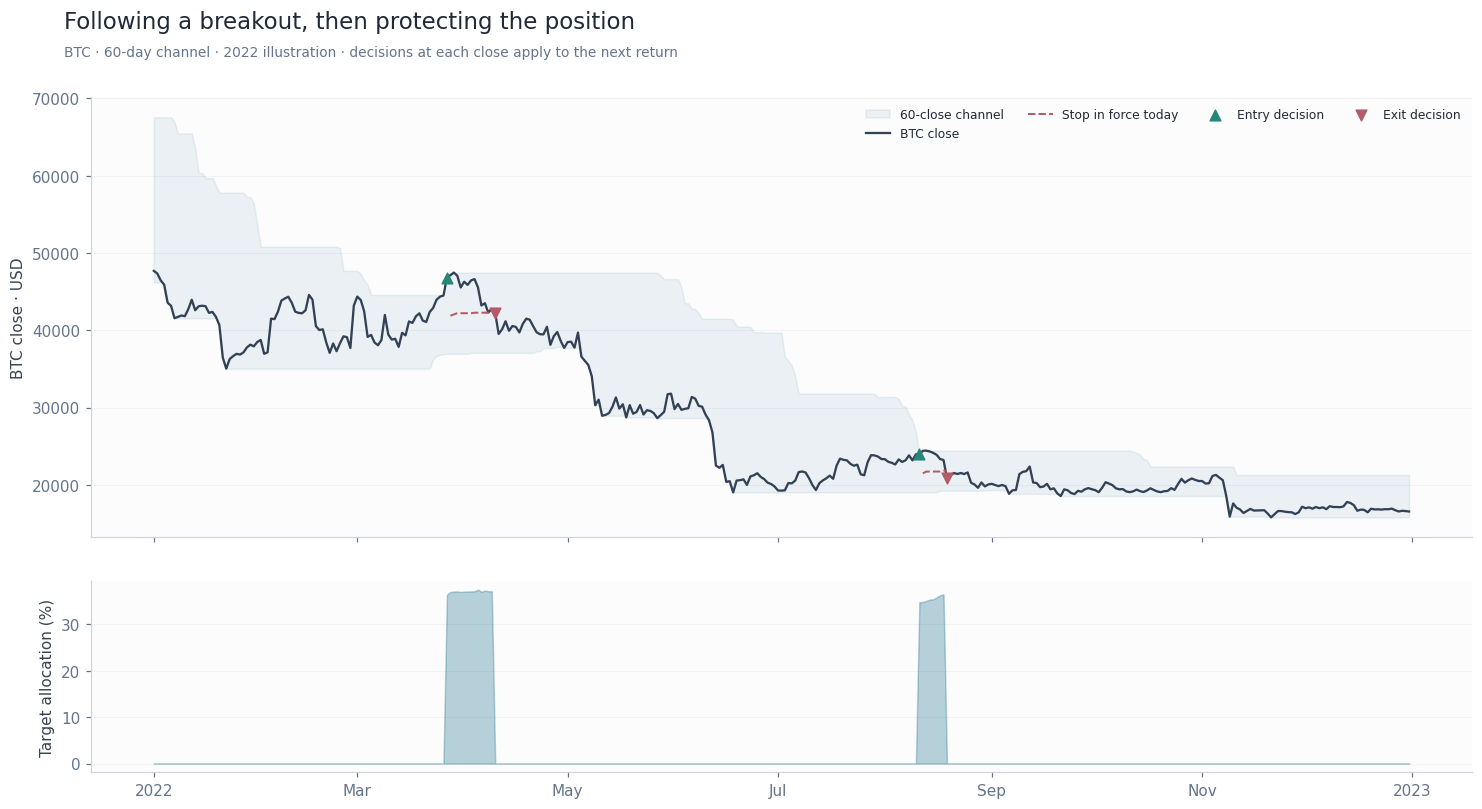

In [5]:
# Fixed instructional window; it is used only to illustrate the equations.
illustration = (prices.index >= "2022-01-01") & (prices.index <= "2022-12-31")

# Dates shown on the horizontal axis for the selected illustration window.
t = prices.index[illustration]

# BTC-only 60-day LO signals: p_t^60, S_t^60, U_t^60, and L_t^60.
p, stops, upper, lower = donchian_states(prices[["BTC-USD"]], 60, "LO")

# Entry marker: p_t changes from cash to long.
entries = (p[:, 0] == 1) & (np.r_[0, p[:-1, 0]] == 0)
# Exit marker: p_t changes from long to cash.
exits = (p[:, 0] == 0) & (np.r_[0, p[:-1, 0]] == 1)

# Figure and axes for the price/channel panel and target-exposure panel.
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})

# U_t^60 and L_t^60: shaded Donchian channel around the BTC closing price.
axes[0].fill_between(t, lower[illustration, 0], upper[illustration, 0], color="#176b87", alpha=.08, label="60-close channel")
# C_t: BTC closing price.

axes[0].plot(t, prices.loc[t, "BTC-USD"], color="#334155", lw=1.5, label="BTC close")
# S_t^60: stop in force before today's midpoint update.

axes[0].plot(t, stops[illustration, 0], color="#b35b66", lw=1.3, ls="--", label="Stop in force today")
# Plot entry and exit decisions at the dates on which p_t changes.

for flag, marker, color, label in [(entries, "^", "#268779", "Entry decision"), (exits, "v", "#b35b66", "Exit decision")]:
    idx = prices.index[illustration & flag]
    axes[0].scatter(idx, prices.loc[idx, "BTC-USD"], marker=marker, s=48, color=color, label=label, zorder=5)
axes[0].set_ylabel("BTC close · USD")
axes[0].legend(ncol=4, fontsize=8, loc="upper right")
# w_t^60: volatility-scaled target allocation for the 60-day LO model.
axes[1].fill_between(t, 0, targets[("LO", "60")][illustration, BTC_I] * 100, color="#176b87", alpha=.3)
axes[1].set_ylabel("Target allocation (%)")
for ax in axes: polish_axis(ax, date_axis=True)
show_figure(fig, "donchian_walkthrough", "Following a breakout, then protecting the position", "BTC · 60-day channel · 2022 illustration · decisions at each close apply to the next return")

## 3. Monthly baskets and daily risk exits

The diversified strategy separates **monthly universe selection** from the daily Donchian
signal. At each month-end, the code screens the fixed 30-coin universe, ranks eligible coins
by reported dollar volume, and forms the basket used during the following month. A coin can
then leave that basket during the month if its liquidity or price-activity condition fails.
There is no performance-based coin selection: the ranking variable is volume.

### Equations and their code variables

Let $V_{i,t}$ be reported dollar volume for coin $i$ on date $t$, and let $C_{i,t}$ be its
closing price. The code uses the following objects:

| Strategy quantity | Code variable | Definition |
|---|---|---|
| $V_{i,t}$ | `volume_frame` | Input daily volume panel |
| Valid $V_{i,t}$ | `valid_volume` | Positive, finite volume; invalid values become missing |
| $\widetilde V^{30}_{i,t}$ | `med30` | Rolling 30-day median valid volume |
| $r_{i,t}$ | `price_frame.pct_change()` | Daily simple price return |
| $A^{30}_{i,t}$ | `medmove` | Rolling 30-day median absolute daily return |
| Current-day volume validity | `invalid_today` | True when today’s volume is missing or nonpositive |
| Daily risk screen | `risk_ok` | Volume, price-activity, and current-day validity test |
| Observed age | `age` | Calendar days since each coin’s first valid price |
| Month-end formation date | `resets[t]` | True when date $t$ is the last calendar day of a month |
| Eligible set | `eligible` | Coins passing age and $\widetilde V^{30}_{i,t}\geq$ `ENTRY_VOLUME` |
| Ranking volume | `month_values` | Median valid volume over the current calendar month |
| Ranked indices | `rank` | Eligible coins ordered from highest to lowest `month_values` |
| Monthly selection | `chosen` | Basket membership carried between month-end resets |
| Daily membership | `membership[t]` | `chosen` after today’s risk screen |

The entry screen is:

$$\mathrm{Eligible}_{i,t}=\mathbf{1}\left\{\mathrm{Age}_{i,t}\geq\texttt{MIN\_HISTORY\_DAYS},\;\widetilde V^{30}_{i,t}\geq\texttt{ENTRY\_VOLUME}\right\}$$

At a month-end formation date, eligible coins are sorted by `month_values`. The arguments
`breadth` and `rank_start` determine which ranked slice is selected:

$$\mathrm{Selected}_t=\mathrm{RankedEligible}_t[\texttt{rank\_start}:\texttt{rank\_start}+\texttt{breadth}]$$

The daily exit screen is:

$$\mathrm{RiskOK}_{i,t}=\mathbf{1}\left\{\widetilde V^{30}_{i,t}\geq\texttt{EXIT\_VOLUME},\;A^{30}_{i,t}\geq\texttt{EXIT\_MOVE},\;V_{i,t}>0\right\}$$

The daily portfolio membership is therefore:

$$\mathrm{Membership}_{i,t}=\mathrm{Chosen}_{i,t}\times\mathrm{RiskOK}_{i,t}$$

A failed daily screen removes a coin for the rest of the current basket period. The code does
not backfill that slot with the next-ranked coin. The resulting slot remains cash until the
next monthly reset. At each reset, the selected capital is equal-weighted across available
slots; the account simulator applies that allocation and lets each coin sleeve compound until
the next reset.

### Function variables

`price_frame` and `volume_frame` are the date-by-coin input panels. `breadth` is the number
of ranked coins requested, while `rank_start` supports selecting an alternate ranked slice;
every basket actually built below uses the default `rank_start=0`. `chosen` is deliberately
persistent: it changes only on month-end dates. `membership` is the full date-by-coin Boolean output after daily
risk exits. `decisions` records the month-end formation audit, including the number of eligible
coins and the number selected before the daily screen.

The code then builds rotating baskets for every breadth from 2 through 30 and selects
`memberships[("rotating", 20, 0)]` as the paper-style 20-coin anchor. This is an adaptation
of the paper’s top-20-liquid strategy to our fixed 30-coin universe; it is not the paper’s
full top-100 liquidity panel.

### Fixed-universe interpretation

The paper's eligibility screen is most valuable when the candidate universe is broad and changes over time. Our candidate universe is already fixed at 30 coins, so the monthly entry screen is not a historical top-30 selection mechanism. It is mainly a data-quality gate applied before ranking those 30 candidates by volume. Most candidates pass after the 30-day warm-up, but the screen is not automatically redundant: in the current CSV and sample, MKR fails the $2 million entry-volume threshold for extended periods.

The daily risk screen remains operationally meaningful. It is evaluated after the monthly basket has been formed and can remove a selected coin when its recent activity deteriorates:

$$
\mathrm{RiskOK}_{i,t}=1 \quad\text{if}\quad
\mathrm{MedianVolume}_{i,t}^{30}\geq\$1{,}000{,}000,\quad
\mathrm{MedianAbsReturn}_{i,t}^{30}\geq0.5\%,\quad
V_{i,t}>0;
\qquad\mathrm{RiskOK}_{i,t}=0\quad\text{otherwise}.
$$

A failed daily screen removes the coin from the active basket and leaves its allocation in cash until the next monthly reset; the code does not replace it with the next-ranked coin. In the current sample, the main recurring failures are concentrated in MKR, TRX, BTC, and ETH, with additional boundary-day failures caused by missing or nonpositive provider volume. These counts are data-dependent and should be recalculated whenever the input CSV is refreshed.

For this fixed-universe study, we can report the monthly entry screen as a diagnostic rather than treating it as evidence that the 30 coins were dynamically discovered. The daily risk exit remains part of the paper-faithful anchor unless we deliberately define a separate fixed-universe experiment without activity exits.

In [6]:
def membership_schedule(price_frame, volume_frame, breadth=20, rank_start=0):
    valid_volume = volume_frame.where(np.isfinite(volume_frame) & (volume_frame>0))
    med30 = valid_volume.rolling(30, min_periods=30).median()
    medmove = price_frame.pct_change(fill_method=None).abs().rolling(30, min_periods=30).median()
    invalid_today = ~np.isfinite(volume_frame) | (volume_frame<=0)
    risk_ok = (med30>=EXIT_VOLUME) & (medmove>=EXIT_MOVE) & ~invalid_today
    age = np.array([(price_frame.index-price_frame[a].first_valid_index()).days for a in price_frame]).T
    chosen = np.zeros(price_frame.shape[1], bool)
    membership = np.zeros(price_frame.shape, bool)
    resets = price_frame.index.is_month_end.to_numpy() if hasattr(price_frame.index.is_month_end, "to_numpy") else price_frame.index.is_month_end.copy()
    decisions = []
    for t, date in enumerate(price_frame.index):
        if resets[t]:
            eligible = (age[t]>=MIN_HISTORY_DAYS) & (med30.iloc[t].to_numpy()>=ENTRY_VOLUME)
            month_values = valid_volume.loc[date.replace(day=1):date].median().to_numpy()
            rank = np.argsort(-np.where(eligible, month_values, -np.inf), kind="stable")
            rank = rank[eligible[rank]][rank_start:rank_start+breadth]
            chosen[:] = False
            chosen[rank] = True
            decisions.append({"formation_date": date, "eligible_coins": int(eligible.sum()),
                              "selected_before_daily_exit": int(chosen.sum())})
        chosen &= risk_ok.iloc[t].to_numpy()
        membership[t] = chosen
    return membership, np.asarray(resets, dtype=bool), pd.DataFrame(decisions)

memberships = {}
for b in range(2, 31): memberships[("rotating", b, 0)] = membership_schedule(prices, volume, b)
main_membership, monthly_resets, selection_audit = memberships[("rotating", 20, 0)]
first_members = np.flatnonzero(main_membership.any(axis=1))
print(f"First eligible basket: {prices.index[first_members[0]].date()} formation close; 365-day observed-history proxy.")
display(selection_audit.iloc[[0, 12, -1]])

First eligible basket: 2022-01-31 formation close; 365-day observed-history proxy.


,formation_date,eligible_coins,selected_before_daily_exit
0,2021-01-31,0,0
12,2022-01-31,30,20
67,2026-08-31,29,20


## 4. Execution and the fixed 20-bps fee

Each coin has a capital account and an asset holding. If no trade occurs, **asset units stay
unchanged**: its weight drifts with price and account equity. Merely carrying yesterday's
weight would imply hidden daily rebalancing, so the engine carries actual dollar holdings.

A signal change in any Combo horizon, monthly basket reset, required exit, or breached
allocation cap forces an update. Otherwise, the 20% rule compares the new target with the
current marked-to-market weight:
$|w^{target}-w^{current}|/|w^{current}|>0.20$.
This relative-current-weight interpretation is fixed for every variant. The zero-threshold
experiment executes all sizing changes. A zero-weight account can enter immediately.

Fees are **0.002 × absolute asset dollars bought or sold**, including initial entry, monthly
changes, signal exits, risk exits, and final liquidation. Transfers of uninvested capital
between coin accounts create no asset trade. A short reversal pays for both closing and opening.
Targets are funded from equity after fees using a scalar accounting identity; there is no
portfolio optimization. Interest on cash, financing, borrow and perpetual funding are zero.
Long–short net returns therefore mean net of the specified trading fee only.

For each day, gross return is the return on the executed post-trade allocation before fees.
If $e_t$ is the entry fee divided by beginning equity and $x_t$ is the final liquidation fee
on the same denominator, net return is $(1-e_t)(1+g_t)-x_t-1$.
Gross and net share the realized exposure path; gross is not a separately resized zero-fee
account. The ledger also reconciles net returns to asset P&L less actual fees.

In [7]:
def after_fee_equity(capital, target, current, cost_rate):
    """Solve equity = capital - fee*|equity*target-current|; no optimizer."""
    result = np.asarray(capital, dtype=float).copy()
    for _ in range(9):
        result = capital-cost_rate*np.abs(result*target-current)
    return result

def simulate_account(target, event, membership, resets, asset_returns, dates,
                     slots, threshold=REBALANCE_THRESHOLD, cost_rate=COST_RATE, keep=False):
    """Inputs already aligned: row k decisions precede row k's asset return."""
    count, assets = asset_returns.shape
    capital = np.zeros(assets)
    risky = np.zeros(assets)
    cash = 1.0
    records = np.zeros((count, 12))
    if keep:
        held = np.zeros((count, assets)); pnl_record = held.copy(); fee_record = held.copy()
        trade_record = held.copy(); final_trade_record = held.copy()
    for t in range(count):
        prior_nav = capital.sum()+cash
        old_risky = risky.copy()
        selected = membership[t]
        desired = np.where(selected, target[t], 0.)
        if t==0 or resets[t]:
            budget = selected.astype(float)/slots
            portfolio_target = budget*desired
            post_nav = prior_nav
            for _ in range(9):
                post_nav = prior_nav-cost_rate*np.abs(post_nav*portfolio_target-old_risky).sum()
            risky = post_nav*portfolio_target
            capital = post_nav*budget
            cash = post_nav*(1-budget.sum())
        else:
            current = np.divide(risky, capital, out=np.zeros(assets), where=capital>1e-15)
            relative_gap = np.abs(desired-current)/np.maximum(np.abs(current), 1e-12)
            force = event[t] | (~selected & (risky!=0)) | (np.abs(current)>MAX_LEVERAGE+1e-12)
            execute = force | (relative_gap>threshold)
            updated = after_fee_equity(capital, desired, risky, cost_rate)
            capital = np.where(execute, updated, capital)
            risky = np.where(execute, updated*desired, risky)
        trade = risky-old_risky
        fee_by_asset = cost_rate*np.abs(trade)
        post_nav = capital.sum()+cash
        if post_nav<=0 or np.any(capital < -1e-12):
            raise ArithmeticError("Account insolvency: review this configuration.")
        weight = risky/post_nav
        pnl = risky*asset_returns[t]
        gross = pnl.sum()/post_nav
        capital += pnl
        risky *= (1+asset_returns[t])
        final_trade = np.zeros(assets)
        exit_fee = 0.
        if t==count-1:
            final_trade = -risky.copy()
            exit_by_asset = cost_rate*np.abs(final_trade)
            exit_fee = exit_by_asset.sum()
            capital -= exit_by_asset
            risky[:] = 0
            fee_by_asset += exit_by_asset
        final_nav = capital.sum()+cash
        if final_nav<=0 or np.any(capital < -1e-12):
            raise ArithmeticError("Account insolvency after returns: review this configuration.")
        turnover = (np.abs(trade).sum()+np.abs(final_trade).sum())/prior_nav
        records[t] = [gross, final_nav/prior_nav-1, fee_by_asset.sum()/prior_nav,
                      turnover, np.abs(weight).sum(), weight.sum(),
                      cost_rate*np.abs(trade).sum()/prior_nav, exit_fee/prior_nav,
                      pnl.sum()/prior_nav, selected.sum(), (np.abs(weight)>1e-12).sum(), final_nav]
        if keep:
            held[t]=weight; pnl_record[t]=pnl/prior_nav; fee_record[t]=fee_by_asset/prior_nav
            trade_record[t]=trade/prior_nav; final_trade_record[t]=final_trade/prior_nav
    frame = pd.DataFrame(records, index=dates, columns=["gross", "net", "cost_paid", "asset_turnover",
        "gross_exposure", "net_exposure", "entry_cost", "exit_cost", "asset_pnl", "eligible_slots", "invested_coins", "net_nav"])
    details = None
    if keep:
        details = {name: pd.DataFrame(values, index=dates, columns=ASSETS) for name, values in
                   [("holding_weights", held), ("asset_pnl", pnl_record), ("asset_fees", fee_record),
                    ("formation_trades", trade_record), ("final_liquidation_trades", final_trade_record)]}
    return frame, details

def make_spec(direction="LO", model="Combo", scope="rotating", breadth=20, asset=None,
              threshold=REBALANCE_THRESHOLD, rank_start=0):
    return dict(direction=direction, model=str(model), scope=scope, breadth=breadth,
                asset=asset, threshold=float(threshold), rank_start=rank_start)

def spec_key(s):
    who = s["asset"].replace("-USD", "") if s["asset"] else str(s["breadth"])
    return f'{s["scope"]}_{who}_{s["direction"]}_{s["model"]}_T{int(100*s["threshold"])}_R{s["rank_start"]}'

def simulate_spec(s, dates, keep=False, cost_rate=COST_RATE):
    idx = prices.index.get_indexer(dates)-1
    target = targets[(s["direction"], s["model"])][idx]
    event = signal_events[(s["direction"], s["model"])][idx]
    if s["scope"] in ["rotating", "liquidity"]:
        members, resets, _ = memberships[(s["scope"], s["breadth"], s["rank_start"])]
        selected, resetting, slots = members[idx], resets[idx], s["breadth"]
    else:
        selected = np.zeros_like(target, dtype=bool)
        selected[:, ASSETS.index(s["asset"])] = True
        resetting, slots = np.zeros(len(idx), bool), 1
    return simulate_account(target, event, selected, resetting, returns.loc[dates].to_numpy(), dates,
                            slots, s["threshold"], cost_rate, keep)

## 5. Backtest selection and validation

All standardized performance tables use daily net returns after trading costs. Total Return and
CAGR describe compounded performance; Sharpe uses the return formula above; volatility and Sortino use 365 days;
and drawdown includes starting wealth of one. Positive Days is the share of daily net returns above
zero. Skewness and Pearson kurtosis describe the daily return distribution.

Alpha, beta, the HAC p-value, and the Information Ratio use the same daily BTC benchmark in both
strategy notebooks. HAC standard errors retain 20 lags. These statistics are descriptive and
unadjusted across the many tested configurations. Selecting the best of 40 backtests creates
selection bias, so validation stability matters more than the winning in-sample rank.


In [8]:
def wealth_and_drawdown(r):
    wealth = (1+r).cumprod()
    return wealth, wealth/wealth.cummax().clip(lower=1)-1

def performance(r, benchmark):
    r = r.dropna()
    benchmark = benchmark.reindex(r.index)
    aligned = pd.concat({"strategy":r, "benchmark":benchmark}, axis=1, sort=True).dropna()
    wealth, dd = wealth_and_drawdown(r)
    sd = r.std(ddof=1)
    downside = np.sqrt(np.mean(np.minimum(r, 0)**2))
    cagr = wealth.iloc[-1]**(365/len(r))-1
    fit = sm.OLS(aligned["strategy"].to_numpy(), sm.add_constant(aligned["benchmark"].to_numpy())).fit(
        cov_type="HAC", cov_kwds={"maxlags":min(HAC_LAGS,len(aligned)-1),"use_correction":True}, use_t=True)
    residual_sd = np.std(fit.resid, ddof=1)
    return {"N dates":len(r), "Total return (%)":100*(wealth.iloc[-1]-1), "CAGR (%)":100*cagr,
            "Volatility (%)":100*sd*np.sqrt(365), "Sharpe":np.sqrt(SHARPE_PERIODS_PER_YEAR)*r.mean()/sd if sd>0 else np.nan,
            "Sortino":np.sqrt(365)*r.mean()/downside if downside>0 else np.nan,
            "Max drawdown (%)":100*dd.min(), "Positive days (%)":100*(r>0).mean(),
            "Alpha vs BTC (%)":36500*fit.params[0], "Beta vs BTC":fit.params[1],
            "Alpha HAC p":fit.pvalues[0], **alpha_uncertainty(fit),
            "Information ratio":fit.params[0]*np.sqrt(365)/residual_sd if residual_sd>1e-12 else np.nan,
            "Skewness":r.skew(), "Pearson kurtosis":r.kurt()+3}

CORE_METRICS = ["Total return (%)","CAGR (%)","Volatility (%)","Sharpe","Sortino",
                "Max drawdown (%)","Positive days (%)","Annual turnover", "Alpha vs BTC (%)", "Alpha HAC t", "Alpha 95% CI low (%)", "Alpha 95% CI high (%)"]
INSTITUTIONAL_METRICS = ["Alpha vs BTC (%)","Beta vs BTC","Alpha HAC p",
                         "Information ratio","Skewness","Pearson kurtosis"]

specifications = {}
def register(s):
    key=spec_key(s); specifications[key]=s; return key
primary_grid = []
for b in BREADTHS:
    for model in MODELS: primary_grid.append(register(make_spec(model=model,breadth=b)))
anchor_key = register(make_spec())
for direction in ["LO","LS"]:
    for model in MODELS: register(make_spec(direction,model,"single",1,"BTC-USD"))
    for b in range(2,31): register(make_spec(direction,breadth=b))
for direction in ["LO","LS"]:
    for model in MODELS: register(make_spec(direction,model,"single",1,"BTC-USD",threshold=0))
register(make_spec(threshold=0))
results, metric_rows = {}, []
def evaluate_keys(keys, period):
    dates = PERIOD_DATES[period]
    btc = returns.loc[dates,"BTC-USD"]
    for key in keys:
        frame,_ = simulate_spec(specifications[key], dates)
        results[(period,key)] = frame
        for basis in ["gross","net"]:
            metric_rows.append({"Period":period,"Strategy":key,"Basis":basis,
                **performance(frame[basis],btc), "Annual turnover":365*frame.asset_turnover.mean(),
                "Mean gross exposure (%)":100*frame.gross_exposure.mean(),
                "Active dates":int((frame.gross_exposure>1e-12).sum())})

evaluate_keys(primary_grid,"Backtest")
first_metrics = pd.DataFrame(metric_rows).set_index(["Period","Strategy","Basis"])
training_ranking = first_metrics.xs(("Backtest","net"),level=("Period","Basis")).reindex(primary_grid).copy()
training_ranking["Declared order"] = np.arange(len(training_ranking))
training_ranking = training_ranking.sort_values(["Sharpe","Annual turnover","Declared order"],ascending=[False,True,True],kind="stable")
selected_key = training_ranking.index[0]
frozen_selection = {"selected_strategy":selected_key,"selected_specification":specifications[selected_key],
    "selection_criterion":"Backtest net Sharpe, ties lower turnover then declared order",
    "candidate_count":len(primary_grid),"backtest_last_date":str(PERIOD_DATES["Backtest"][-1].date())}
print("Backtest selection frozen:", specifications[selected_key])
evaluate_keys([k for k in specifications if k not in primary_grid],"Backtest")
# Validation is evaluated only after the selection above has been frozen.
evaluate_keys(list(specifications),"Validation")
metrics = pd.DataFrame(metric_rows).set_index(["Period","Strategy","Basis"])
print(f"Evaluated {len(specifications)} declared configurations in each segment; all net returns use {COST_BPS} bps.")


Backtest selection frozen: {'direction': 'LO', 'model': '20', 'scope': 'rotating', 'breadth': 30, 'asset': None, 'threshold': 0.2, 'rank_start': 0}


Evaluated 135 declared configurations in each segment; all net returns use 20 bps.


## 6. Bitcoin: horizon, ensemble, and threshold comparisons

The horizon tables report the standardized core metrics using net returns after 20-bps costs.
The accompanying chart retains gross and net Sharpe so the effect of costs remains visible without
duplicating every table. Horizon order is fixed when comparing backtest and validation.


### Backtest: BTC LO, net at 20 bps

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
5,17.6729,4.1524,15.4133,0.2826,0.5704,-24.5137,14.5890,24.8713,-0.2487,-0.0314,-15.7780,15.2807
10,22.3052,5.1626,14.3193,0.3510,0.6923,-23.4993,14.1781,13.5631,1.2504,0.1647,-13.6383,16.1390
20,39.9814,8.7721,14.9896,0.5280,1.0099,-20.2789,15.5479,7.7339,4.4170,0.5932,-10.1887,19.0226
30,55.9977,11.7582,15.2643,0.6681,1.3168,-20.4478,14.8630,4.6238,6.9545,0.9665,-7.1600,21.0690
60,78.7674,15.6304,15.4532,0.8446,1.6991,-11.7891,15.2055,2.2050,10.3498,1.4442,-3.7078,24.4075
90,49.4487,10.5664,15.5480,0.6010,1.1621,-17.7312,15.3425,1.8083,5.8877,0.8610,-7.5253,19.3007
150,37.9823,8.3817,15.4828,0.4960,0.9290,-19.2822,17.2603,1.5405,3.7433,0.5332,-10.0270,17.5136
250,74.0934,14.8671,17.1670,0.7418,1.4361,-14.1031,19.9315,1.0628,8.9242,1.0859,-7.1971,25.0454
360,104.7257,19.6170,16.8950,0.9507,1.9040,-13.8216,19.5205,0.5389,13.0779,1.6495,-2.4747,28.6305
Combo,51.2187,10.8923,13.0541,0.7120,1.4171,-11.2046,29.7260,5.9886,5.7983,0.9604,-6.0449,17.6416


### Backtest: BTC LS, net at 20 bps

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
5,-28.3325,-7.9909,20.6742,-0.2494,-0.4550,-40.6940,27.3973,50.3170,-6.1018,-0.5602,-27.4682,15.2646
10,11.8910,2.8487,19.8942,0.1996,0.3670,-24.7029,26.7123,24.5001,5.2666,0.5190,-14.6385,25.1716
20,25.1969,5.7787,19.9310,0.3167,0.5756,-26.7910,27.3288,13.8703,7.2881,0.7086,-12.8860,27.4621
30,38.1967,8.4238,19.9616,0.4192,0.7713,-29.4925,26.5068,9.2243,9.4204,0.8833,-11.5011,30.3419
60,44.4012,9.6207,20.0390,0.4637,0.8543,-30.0322,28.0822,5.2405,10.5184,1.0012,-10.0898,31.1266
90,25.7428,5.8939,20.2648,0.3186,0.5771,-29.0964,28.0137,3.7709,7.5477,0.7250,-12.8738,27.9692
150,38.5310,8.4893,20.2678,0.4180,0.7575,-28.4859,30.8219,2.6292,10.0552,0.9600,-10.4902,30.6005
250,77.7496,15.4655,20.3969,0.6701,1.2609,-29.6909,30.1370,1.6470,13.7333,1.2020,-8.6777,36.1443
360,75.4700,15.0935,20.8709,0.6460,1.1976,-38.9566,31.5753,1.1915,14.2555,1.2481,-8.1495,36.6605
Combo,30.8346,6.9500,14.8585,0.4370,0.8446,-22.1264,33.9726,11.9879,7.3593,0.8869,-8.9177,23.6364


### Validation: BTC LO, net at 20 bps

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
5,-19.2836,-11.7600,15.4161,-0.6105,-1.0786,-29.7422,19.5200,43.4730,-10.8844,-1.1275,-29.8424,8.0737
10,-2.3228,-1.3632,13.0917,-0.0328,-0.0572,-16.0268,16.6400,19.8360,-0.1909,-0.0264,-14.3908,14.0091
20,-2.2602,-1.3262,12.8980,-0.0325,-0.0564,-19.5496,15.6800,10.3062,-0.1926,-0.0236,-16.2393,15.8541
30,-8.2029,-4.8755,12.7786,-0.2720,-0.4622,-21.2832,15.0400,8.4401,-3.8849,-0.4867,-19.5600,11.7901
60,-12.5453,-7.5299,12.5022,-0.4683,-0.7790,-21.5994,15.5200,5.8051,-6.7582,-0.8587,-22.2129,8.6964
90,-9.8169,-5.8559,12.4629,-0.3504,-0.5714,-21.9652,15.8400,3.9366,-4.9764,-0.6599,-19.7847,9.8318
150,-6.2120,-3.6761,15.3294,-0.1391,-0.2252,-16.0188,16.9600,1.6886,-2.1585,-0.2548,-18.7972,14.4802
250,-15.2877,-9.2345,17.0186,-0.4021,-0.6410,-20.6502,19.5200,1.6763,-7.7482,-0.8512,-25.6246,10.1281
360,-15.2877,-9.2345,17.0186,-0.4021,-0.6410,-20.6502,19.5200,1.6763,-7.7482,-0.8512,-25.6246,10.1281
Combo,-9.1593,-5.4556,10.7794,-0.3875,-0.6248,-16.5629,37.7600,10.2399,-4.6658,-0.9285,-14.5338,5.2023


### Validation: BTC LS, net at 20 bps

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
5,-29.3265,-18.3482,23.6559,-0.6141,-1.0771,-36.0087,38.0800,87.9306,-17.6915,-1.0024,-52.3510,16.9680
10,-9.1758,-5.4656,22.1820,-0.1187,-0.2088,-23.6499,34.8800,43.8882,-3.4703,-0.2309,-32.9845,26.0438
20,-10.6748,-6.3800,22.1443,-0.1557,-0.2735,-31.0619,34.0800,23.0951,-4.4715,-0.2515,-39.3924,30.4495
30,-2.0697,-1.2140,22.2531,0.0465,0.0819,-29.3299,33.4400,16.0492,0.8959,0.0541,-31.6139,33.4057
60,9.6001,5.4993,22.7681,0.2895,0.5184,-16.9657,38.4000,9.0604,7.4896,0.4992,-21.9728,36.9521
90,1.2355,0.7197,24.0970,0.1246,0.2159,-22.4814,42.4000,6.5498,3.0510,0.2113,-25.3046,31.4067
150,-16.4685,-9.9755,23.0429,-0.2832,-0.4677,-24.2543,37.7600,4.2860,-8.0520,-0.5275,-38.0303,21.9263
250,-15.2764,-9.2275,23.1429,-0.2514,-0.4123,-20.6502,36.6400,3.1501,-7.0090,-0.4077,-40.7668,26.7488
360,-19.8075,-12.0949,23.3287,-0.3620,-0.5852,-27.6146,38.0800,2.9829,-10.1826,-0.6225,-42.3069,21.9416
Combo,-9.1348,-5.4407,15.6927,-0.2313,-0.3975,-17.2783,43.8400,21.3115,-4.6364,-0.4480,-24.9592,15.6863


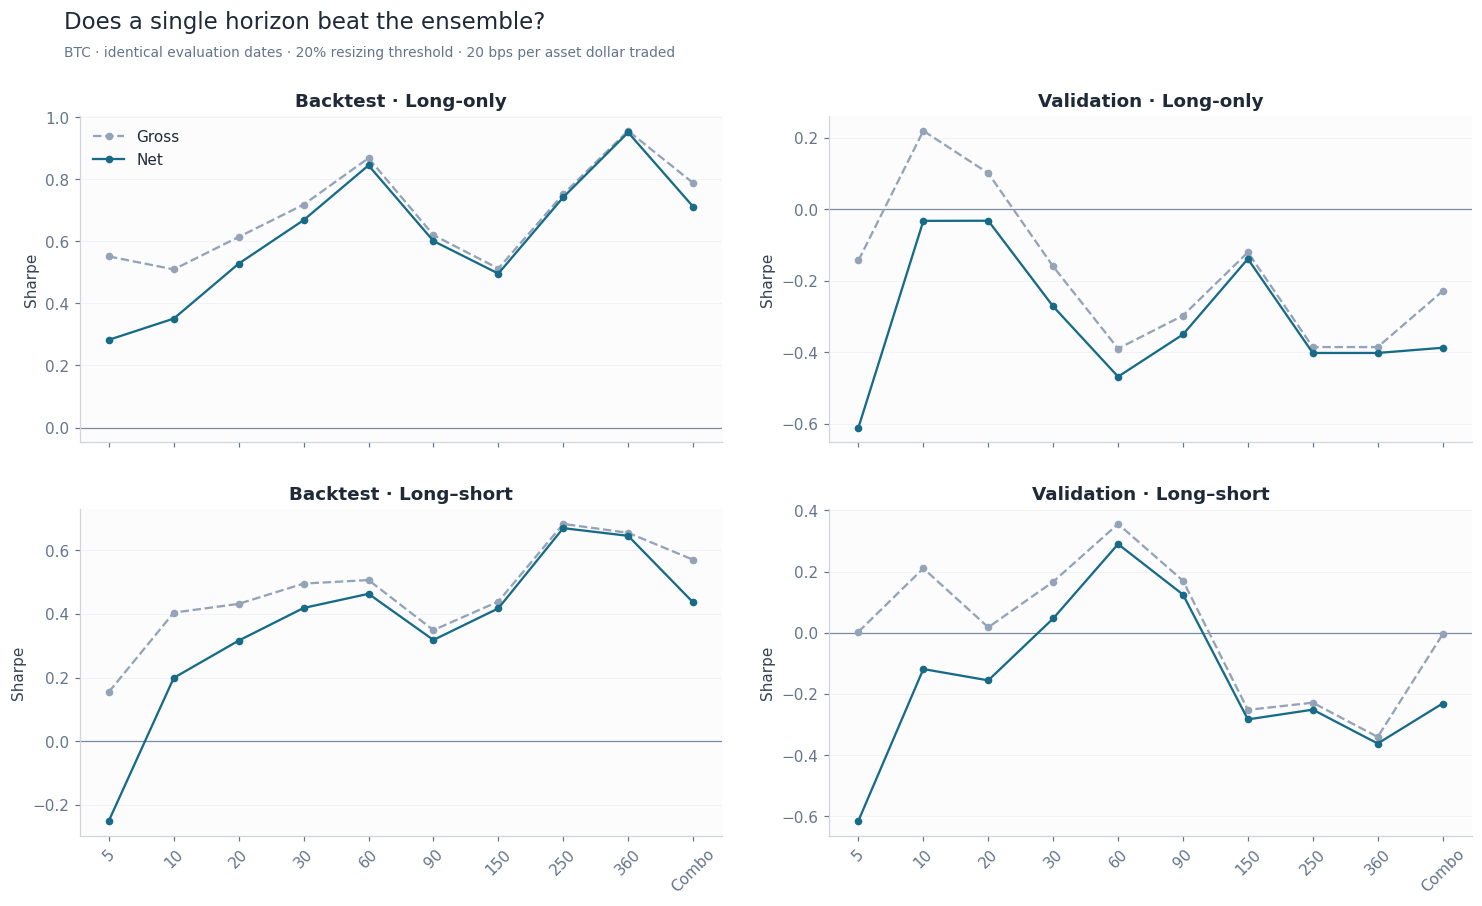

In [9]:
def table_for(keys, period, basis="net", labels=None, columns=CORE_METRICS):
    table = metrics.xs((period,basis),level=("Period","Basis")).reindex(keys)[columns]
    if labels is not None: table.index=labels
    return table

for period in PERIOD_DATES:
    for direction in ["LO","LS"]:
        keys=[spec_key(make_spec(direction,m,"single",1,"BTC-USD")) for m in MODELS]
        display(Markdown(f"### {period}: BTC {direction}, net at 20 bps"))
        display(table_for(keys,period,labels=MODELS))

fig,axes=plt.subplots(2,2,figsize=(14,8.4),sharex=True)
for row,direction in enumerate(["LO","LS"]):
    for col,period in enumerate(PERIOD_DATES):
        ax=axes[row,col]
        keys=[spec_key(make_spec(direction,m,"single",1,"BTC-USD")) for m in MODELS]
        for basis,color,ls in [("gross","#94a3b8","--"),("net","#176b87","-")]:
            values=[metrics.loc[(period,k,basis),"Sharpe"] for k in keys]
            ax.plot(range(10),values,marker="o",ms=4,color=color,ls=ls,label=basis.capitalize())
        ax.set_title(f"{period} · {'Long-only' if direction=='LO' else 'Long–short'}")
        ax.set_xticks(range(10),MODELS,rotation=45)
        ax.set_ylabel("Sharpe")
        polish_axis(ax,zero_line=True)
axes[0,0].legend()
show_figure(fig,"btc_horizon_comparison","Does a single horizon beat the ensemble?","BTC · identical evaluation dates · 20% resizing threshold · 20 bps per asset dollar traded")


Net Sharpe  Annual turnover
Period     Model Threshold rule                             
Backtest   5     Daily resize        0.2419          25.3261
                 20% threshold       0.2826          24.8713
           10    Daily resize        0.3042          14.0736
                 20% threshold       0.3510          13.5631
           20    Daily resize        0.4663           8.2776
                 20% threshold       0.5280           7.7339
           30    Daily resize        0.6326           5.1889
                 20% threshold       0.6681           4.6238
           60    Daily resize        0.8652           2.7051
                 20% threshold       0.8446           2.2050
           90    Daily resize        0.6079           2.3515
                 20% threshold       0.6010           1.8083
           150   Daily resize        0.4927           2.1863
                 20% threshold       0.4960           1.5405
           250   Daily resize        0.7173           1.7688
                 20% threshold       0.7418           1.0628
           360   Daily resize        0.9365           1.2108
                 20% threshold       0.9507           0.5389
           Combo Daily resize        0.7035           6.5252
                 20% threshold       0.7120           5.9886
Validation 5     Daily resize       -0.6512          43.9677
                 20% threshold      -0.6105          43.4730
           10    Daily resize       -0.0430          20.3459
                 20% threshold      -0.0328          19.8360
           20    Daily resize       -0.0388          10.9129
                 20% threshold      -0.0325          10.3062
           30    Daily resize       -0.3253           9.1340
                 20% threshold      -0.2720           8.4401
           60    Daily resize       -0.4874           6.5405
                 20% threshold      -0.4683           5.8051
           90    Daily resize       -0.3404           4.5186
                 20% threshold      -0.3504           3.9366
           150   Daily resize       -0.1143           2.2640
                 20% threshold      -0.1391           1.6886
           250   Daily resize       -0.3457           2.3108
                 20% threshold      -0.4021           1.6763
           360   Daily resize       -0.3457           2.3108
                 20% threshold      -0.4021           1.6763
           Combo Daily resize       -0.3863          10.8037
                 20% threshold      -0.3875          10.2399

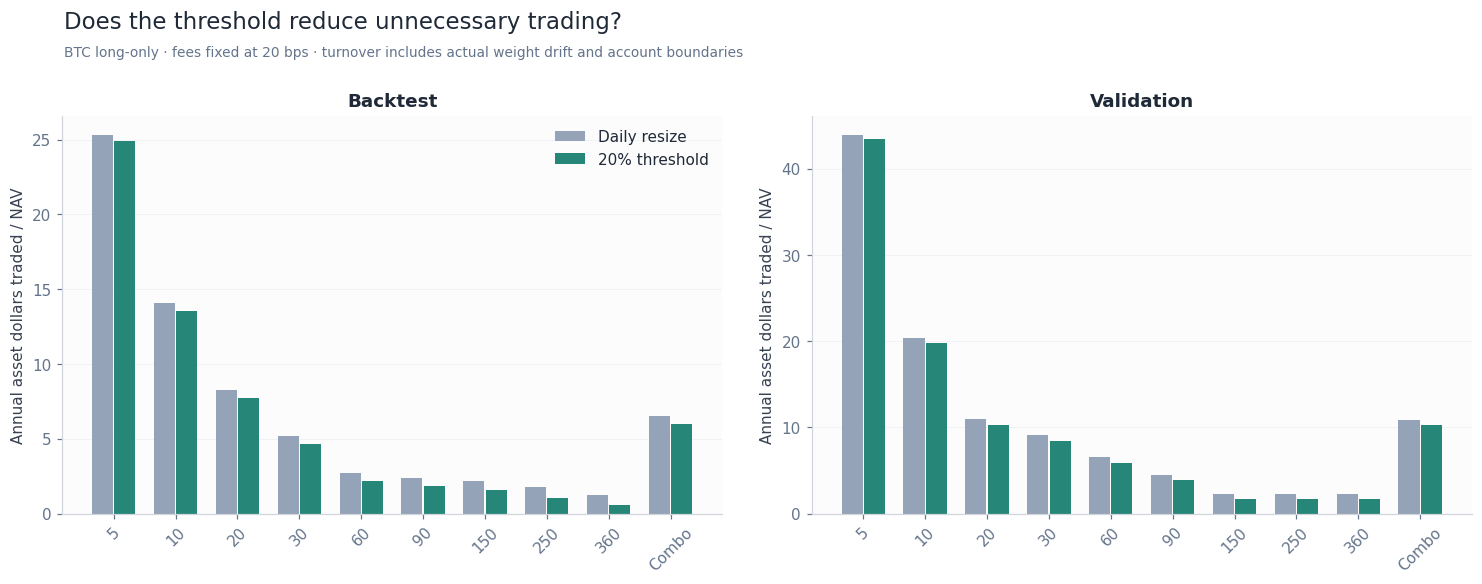

In [10]:
threshold_rows=[]
for period in PERIOD_DATES:
    for model in MODELS:
        for threshold,label in [(0,"Daily resize"),(.2,"20% threshold")]:
            key=spec_key(make_spec("LO",model,"single",1,"BTC-USD",threshold=threshold))
            metric=metrics.loc[(period,key,"net")]
            threshold_rows.append({"Period":period,"Model":model,"Threshold rule":label,
                "Net Sharpe":metric["Sharpe"],"Annual turnover":metric["Annual turnover"]})
threshold_table=pd.DataFrame(threshold_rows).set_index(["Period","Model","Threshold rule"])
display(threshold_table)

fig,axes=plt.subplots(1,2,figsize=(14,5.4))
for ax,period in zip(axes,PERIOD_DATES):
    for offset,label,color in [(-.18,"Daily resize","#94a3b8"),(.18,"20% threshold","#268779")]:
        values=threshold_table.xs((period,label),level=("Period","Threshold rule")).reindex(MODELS)["Annual turnover"]
        ax.bar(np.arange(10)+offset,values,width=.34,label=label,color=color)
    ax.set_xticks(range(10),MODELS,rotation=45)
    ax.set_title(period); ax.set_ylabel("Annual asset dollars traded / NAV"); polish_axis(ax)
axes[0].legend()
show_figure(fig,"threshold_turnover","Does the threshold reduce unnecessary trading?","BTC long-only · fees fixed at 20 bps · turnover includes actual weight drift and account boundaries")


### Trade-level context

The following unit-trade table isolates the channel signal from risk sizing: one coin is
bought or shorted at the entry close and closed at the signal exit/reversal close. It uses
gross unit-price P&L. Only trades with both entry and exit inside a segment after common warm-up are summarized; boundary-censored trades are counted separately. Combo has fractional overlapping signals and is not forced into artificial single-trade episodes.

In [11]:
trade_rows=[]; trade_summary=[]
for period,dates in PERIOD_DATES.items():
    formation_dates=prices.index[prices.index.get_indexer(dates)-1]
    for direction in ["LO","LS"]:
        for N in LOOKBACKS:
            state=signal_states[(direction,str(N))][:,BTC_I].copy()
            state[~common_ready]=0
            open_at=None; sign=0.; completed=[]; censored=0
            for t in range(len(prices)):
                if state[t]==sign: continue
                if sign and open_at is not None:
                    entry_date,exit_date=prices.index[open_at],prices.index[t]
                    if entry_date>=formation_dates[0] and exit_date<=dates[-1]:
                        entry_price=prices.iloc[open_at,BTC_I]; exit_price=prices.iloc[t,BTC_I]
                        rec={"Period":period,"Direction":direction,"Horizon":N,"Entry":entry_date,"Exit":exit_date,
                             "Side":sign,"Days":t-open_at,"Unit PnL (USD)":sign*(exit_price-entry_price),
                             "Unit return (%)":100*sign*(exit_price/entry_price-1)}
                        trade_rows.append(rec); completed.append(rec)
                    elif entry_date<=dates[-1] and exit_date>=formation_dates[0]: censored+=1
                sign=state[t]; open_at=t if sign else None
            if sign and open_at is not None and prices.index[open_at]<=dates[-1]: censored+=1
            values=np.array([r["Unit return (%)"] for r in completed])
            trade_summary.append({"Period":period,"Direction":direction,"Horizon":N,
                "Completed trades":len(values),"Boundary-censored trades":censored,
                "Win rate (%)":100*np.mean(values>0) if len(values) else np.nan,
                "Mean holding days":np.mean([r["Days"] for r in completed]) if completed else np.nan,
                "Mean unit return (%)":values.mean() if len(values) else np.nan})
unit_trade_ledger=pd.DataFrame(trade_rows)
unit_trade_summary=pd.DataFrame(trade_summary).set_index(["Period","Direction","Horizon"])
display(unit_trade_summary)


Completed trades  Boundary-censored trades  \
Period     Direction Horizon                                               
Backtest   LO        5                     101                         0   
                     10                     56                         0   
                     20                     31                         0   
                     30                     18                         0   
                     60                      7                         1   
                     90                      5                         1   
                     150                     4                         1   
                     250                     2                         1   
                     360                     0                         1   
           LS        5                     204                         1   
                     10                     98                         1   
                     20                     54                         1   
                     30                     35                         1   
                     60                     18                         1   
                     90                     12                         1   
                     150                     7                         1   
                     250                     3                         1   
                     360                     1                         1   
Validation LO        5                      63                         0   
                     10                     28                         0   
                     20                     14                         0   
                     30                     10                         1   
                     60                      6                         2   
                     90                      3                         2   
                     150                     1                         1   
                     250                     1                         1   
                     360                     1                         1   
           LS        5                     124                         2   
                     10                     59                         2   
                     20                     29                         2   
                     30                     19                         2   
                     60                     10                         2   
                     90                      6                         2   
                     150                     4                         1   
                     250                     2                         1   
                     360                     1                         2   

                              Win rate (%)  Mean holding days  \
Period     Direction Horizon                                    
Backtest   LO        5             35.6436             4.6931   
                     10            28.5714             8.1250   
                     20            32.2581            14.9032   
                     30            33.3333            24.8333   
                     60            57.1429            50.5714   
                     90            60.0000            75.4000   
                     150           50.0000           112.2500   
                     250           50.0000           264.5000   
                     360               NaN                NaN   
           LS        5             33.8235             4.3775   
                     10            33.6735             8.4796   
                     20            33.3333            15.0000   
                     30            34.2857            22.7429   
                     60            38.8889            40.5000   
                     90            41.6667            62.0833   
                     150           4

## 7. Diversified strategies: breadth and horizon

The table first tests the paper's preferred Combo across the feasible published basket sizes.
The two-dimensional grid then tests whether that ensemble is competitive with individual
horizons on our diversified universe. **The highlighted strategy was selected on backtest
net Sharpe alone.** Validation grids show transfer and instability; their maxima are not
used to replace the frozen selection. Fine breadth curves include concentrated portfolios
as descriptive evidence, not additional candidates for the primary selection.

### Backtest: LO Combo, net at 20 bps

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
Top 5,18.4401,4.3217,8.2867,0.4586,0.8230,-12.5515,32.6712,4.4409,1.4603,0.3546,-6.6191,9.5397
Top 10,31.3221,7.0494,7.6637,0.7704,1.4306,-10.0967,35.6164,4.2339,4.4471,0.9737,-4.5121,13.4062
Top 20,28.3467,6.4379,7.0959,0.7601,1.4142,-8.1618,35.6164,3.7982,4.2439,1.0262,-3.8680,12.3557
Top 30,35.0139,7.7940,7.0653,0.9120,1.7287,-8.4784,36.3014,3.5402,5.6301,1.2183,-3.4347,14.6950


### Backtest: LS Combo, net at 20 bps

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
Top 5,3.8926,0.9593,10.2476,0.1198,0.2174,-22.1036,34.9315,9.2987,2.3181,0.4045,-8.9223,13.5586
Top 10,11.4280,2.7421,9.3015,0.2802,0.5097,-19.3681,34.1781,8.8717,4.2084,0.7805,-6.3681,14.7848
Top 20,12.3569,2.9556,9.2688,0.2995,0.5492,-15.0743,35.1370,8.2851,5.0358,1.0485,-4.3859,14.4575
Top 30,16.4507,3.8808,9.4206,0.3749,0.6853,-13.4337,35.3425,7.9494,6.2543,1.2524,-3.5419,16.0505


### Validation: LO Combo, net at 20 bps

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
Top 5,-0.5910,-0.3456,8.2588,-0.0006,-0.0010,-11.2395,44.8000,7.0779,0.2370,0.0493,-9.2136,9.6876
Top 10,-4.4518,-2.6244,6.7258,-0.3006,-0.4983,-11.0334,45.7600,6.3479,-2.2447,-0.6097,-9.4744,4.9850
Top 20,-4.0628,-2.3931,5.6807,-0.3307,-0.5488,-9.5728,48.9600,5.3876,-2.1060,-0.6646,-8.3290,4.1170
Top 30,-4.4174,-2.6039,5.0435,-0.4137,-0.6871,-9.0697,49.4400,4.9032,-2.3794,-0.8391,-7.9478,3.1890


### Validation: LS Combo, net at 20 bps

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
Top 5,-2.6712,-1.5688,12.9312,-0.0481,-0.0823,-10.4463,49.9200,14.8297,-1.0554,-0.1334,-16.5954,14.4846
Top 10,-6.6134,-3.9171,11.0272,-0.2553,-0.4202,-9.9971,51.6800,13.5850,-3.6859,-0.6109,-15.5346,8.1628
Top 20,-7.3608,-4.3669,10.5639,-0.3073,-0.4973,-10.4778,52.3200,12.1799,-4.2459,-0.7777,-14.9670,6.4752
Top 30,-6.7686,-4.0104,10.4794,-0.2810,-0.4548,-10.3316,51.6800,11.5214,-3.9104,-0.8225,-13.2469,5.4262


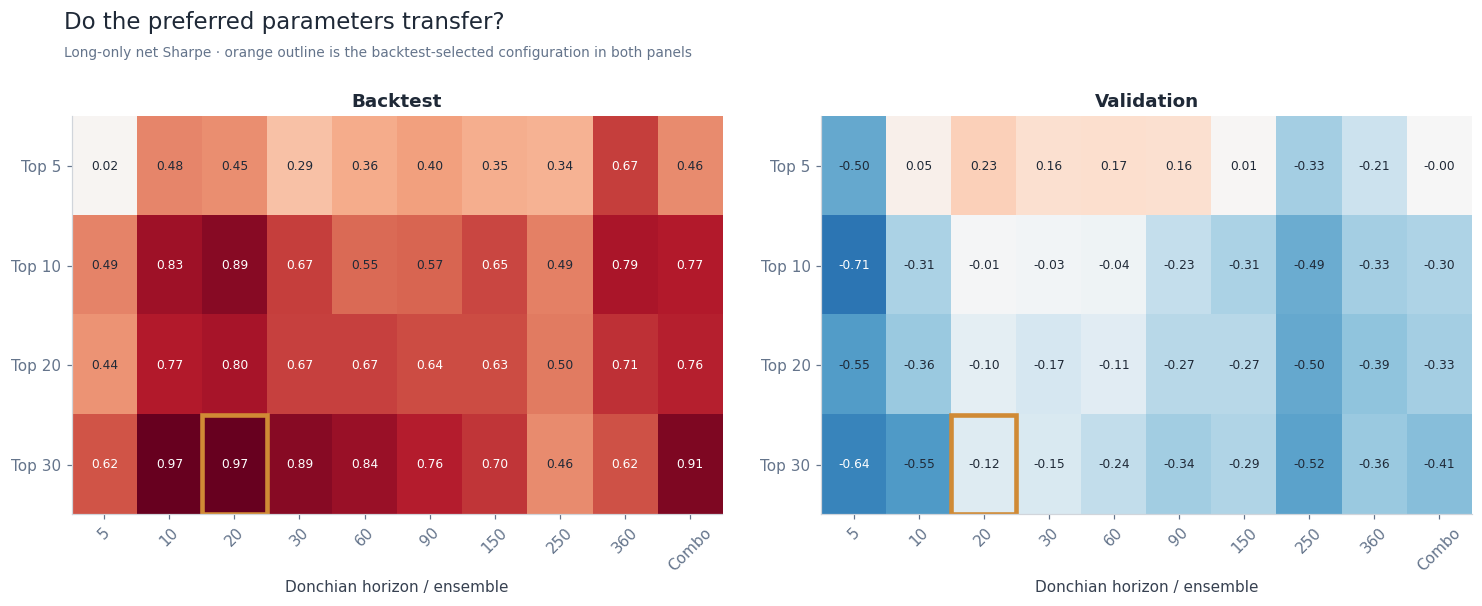

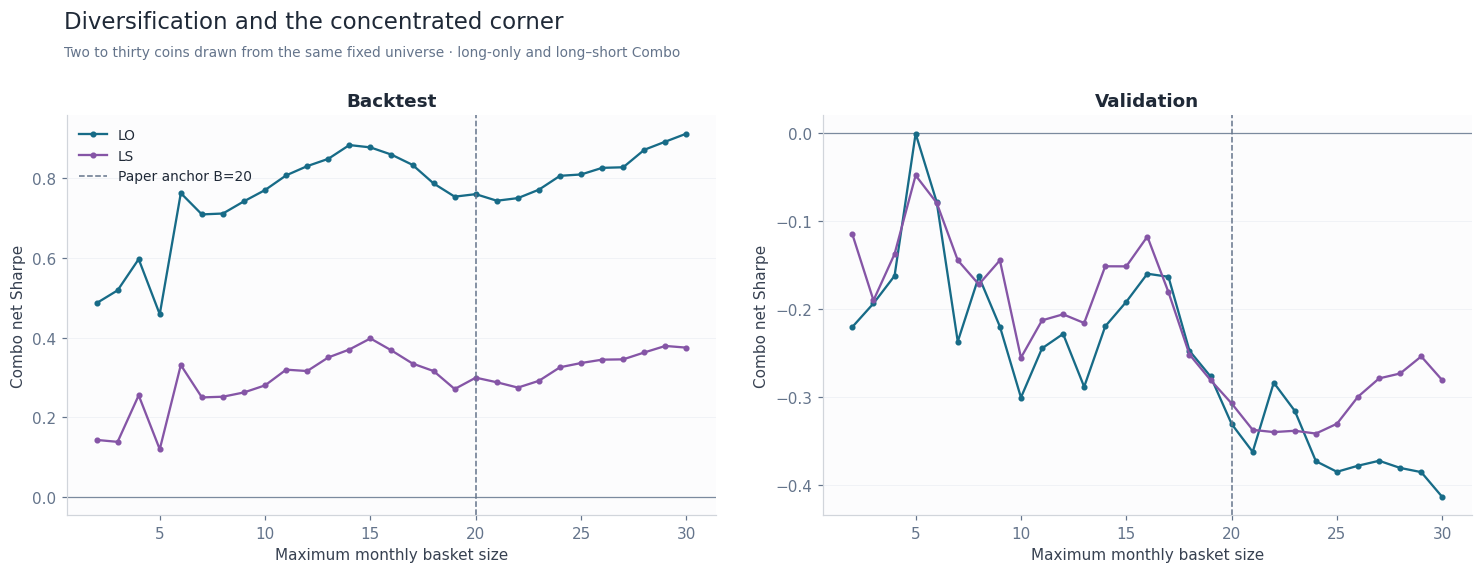

In [12]:
for period in PERIOD_DATES:
    for direction in ["LO","LS"]:
        keys=[spec_key(make_spec(direction,breadth=b)) for b in BREADTHS]
        display(Markdown(f"### {period}: {direction} Combo, net at 20 bps"))
        display(table_for(keys,period,labels=[f"Top {b}" for b in BREADTHS]))

grid_tables={}
for period in PERIOD_DATES:
    grid_tables[period]=pd.DataFrame([[metrics.loc[(period,spec_key(make_spec(model=m,breadth=b)),"net"),"Sharpe"]
                                     for m in MODELS] for b in BREADTHS],index=BREADTHS,columns=MODELS)
vmax=max(abs(x.to_numpy()).max() for x in grid_tables.values())
fig,axes=plt.subplots(1,2,figsize=(14,5.6))
for ax,(period,table) in zip(axes,grid_tables.items()):
    ax.imshow(table,cmap="RdBu_r",vmin=-vmax,vmax=vmax,aspect="auto")
    for (r,c),v in np.ndenumerate(table.to_numpy()):
        ax.text(c,r,f"{v:.2f}",ha="center",va="center",fontsize=8,color="white" if abs(v)>.6*vmax else "#1f2937")
    selected=specifications[selected_key]
    from matplotlib.patches import Rectangle
    ax.add_patch(Rectangle((MODELS.index(selected["model"])-.5,BREADTHS.index(selected["breadth"])-.5),1,1,
                           fill=False,edgecolor="#d08a35",lw=3))
    ax.set_xticks(range(10),MODELS,rotation=45); ax.set_yticks(range(4),[f"Top {b}" for b in BREADTHS])
    ax.set_title(period); ax.set_xlabel("Donchian horizon / ensemble")
show_figure(fig,"horizon_breadth_grid","Do the preferred parameters transfer?","Long-only net Sharpe · orange outline is the backtest-selected configuration in both panels")

fig,axes=plt.subplots(1,2,figsize=(14,5.3))
for ax,period in zip(axes,PERIOD_DATES):
    for direction,color in [("LO","#176b87"),("LS","#8555a6")]:
        values=[metrics.loc[(period,spec_key(make_spec(direction,breadth=b)),"net"),"Sharpe"] for b in range(2,31)]
        ax.plot(range(2,31),values,marker="o",ms=3,lw=1.5,color=color,label=direction)
    ax.axvline(20,color="#64748b",ls="--",lw=1,label="Paper anchor B=20")
    ax.set_title(period); ax.set_xlabel("Maximum monthly basket size"); ax.set_ylabel("Combo net Sharpe")
    polish_axis(ax,zero_line=True)
axes[0].legend(fontsize=9)
show_figure(fig,"breadth_curve","Diversification and the concentrated corner","Two to thirty coins drawn from the same fixed universe · long-only and long–short Combo")

## 8. Standardized daily performance and representative accounts

The standardized tables use daily net returns and the common performance definitions. The first
table contains return and risk measures; the second retains alpha, beta, HAC significance,
Information Ratio, skewness, and kurtosis. The plots focus on the paper anchor, frozen backtest
selection, long–short reference, and market benchmarks.


### Backtest: standardized net performance

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
Paper anchor · LO Combo / B=20,28.3467,6.4379,7.0959,0.7601,1.4142,-8.1618,35.6164,3.7982,4.2439,1.0262,-3.8680,12.3557
Selected · LO 20d / B=30,53.6934,11.3432,9.5517,0.9744,1.8455,-11.8562,31.3699,4.1632,8.7126,1.3730,-3.7349,21.1602
Long–short reference · Combo / B=20,12.3569,2.9556,9.2688,0.2995,0.5492,-15.0743,35.1370,8.2851,5.0358,1.0485,-4.3859,14.4575


**Distribution and benchmark diagnostics**

,Alpha vs BTC (%),Beta vs BTC,Alpha HAC p,Information ratio,Skewness,Pearson kurtosis
Paper anchor · LO Combo / B=20,4.2439,0.0468,0.3049,0.6550,0.4207,18.8984
Selected · LO 20d / B=30,8.7126,0.0518,0.1700,0.9683,0.6204,20.0285
Long–short reference · Combo / B=20,5.0358,-0.0353,0.2946,0.5590,0.7540,21.3081


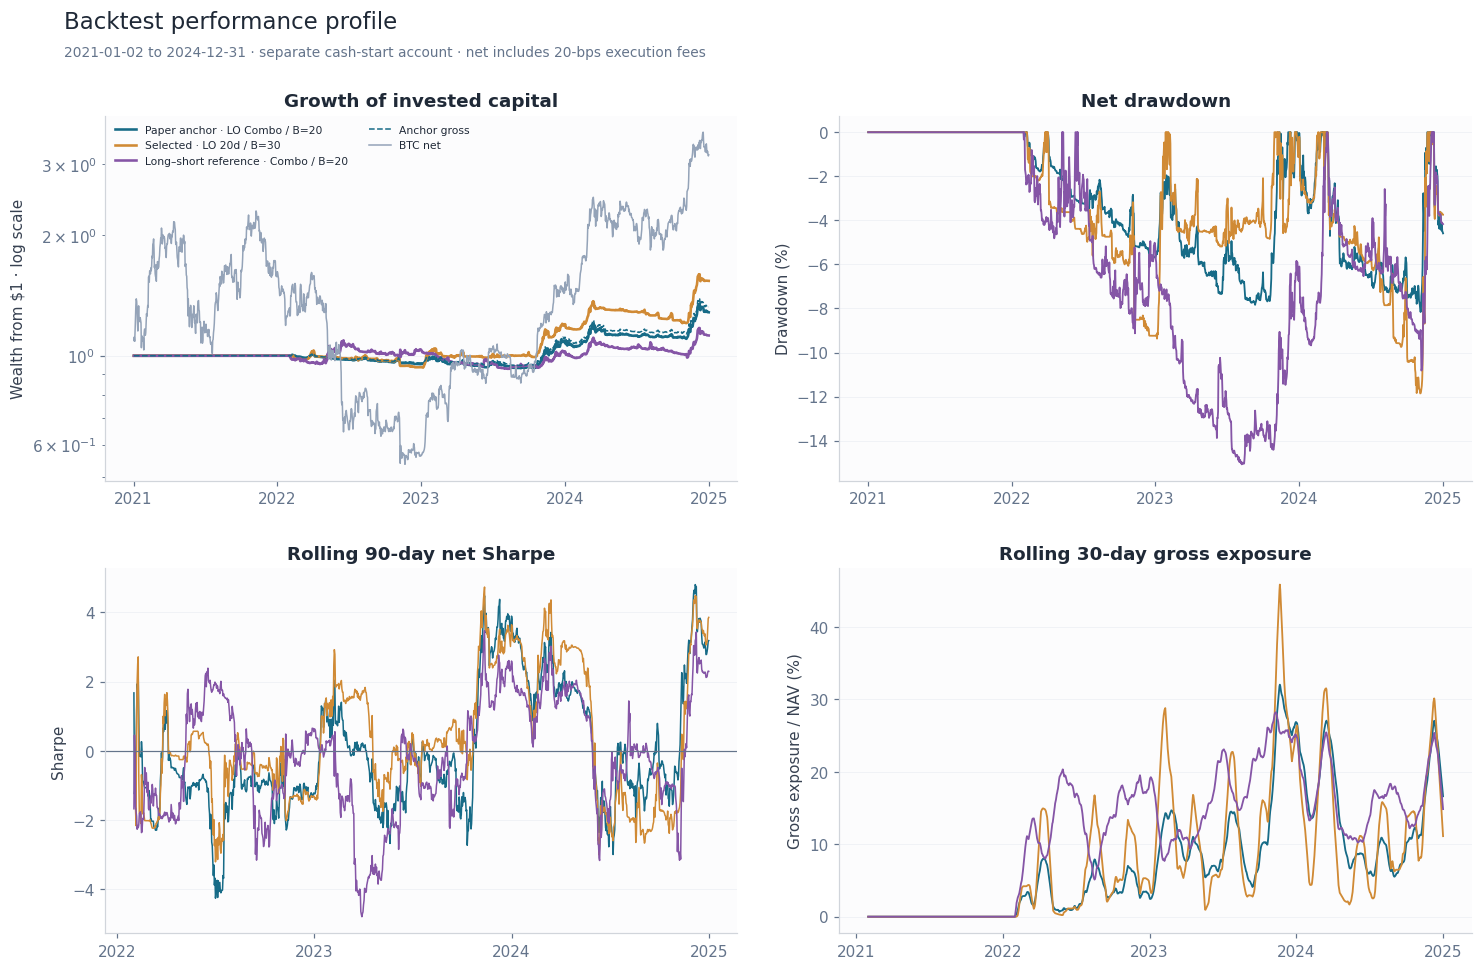

### Validation: standardized net performance

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
Paper anchor · LO Combo / B=20,-4.0628,-2.3931,5.6807,-0.3307,-0.5488,-9.5728,48.9600,5.3876,-2.1060,-0.6646,-8.3290,4.1170
Selected · LO 20d / B=30,-2.3815,-1.3978,7.6205,-0.1220,-0.2230,-13.7080,40.1600,5.3472,-0.9569,-0.1729,-11.8257,9.9119
Long–short reference · Combo / B=20,-7.3608,-4.3669,10.5639,-0.3073,-0.4973,-10.4778,52.3200,12.1799,-4.2459,-0.7777,-14.9670,6.4752


**Distribution and benchmark diagnostics**

,Alpha vs BTC (%),Beta vs BTC,Alpha HAC p,Information ratio,Skewness,Pearson kurtosis
Paper anchor · LO Combo / B=20,-2.1060,0.0700,0.5066,-0.4400,-0.0971,12.3912
Selected · LO 20d / B=30,-0.9569,0.0732,0.8628,-0.1383,1.5541,26.3309
Long–short reference · Combo / B=20,-4.2459,-0.1530,0.4370,-0.5190,-0.1917,18.4338


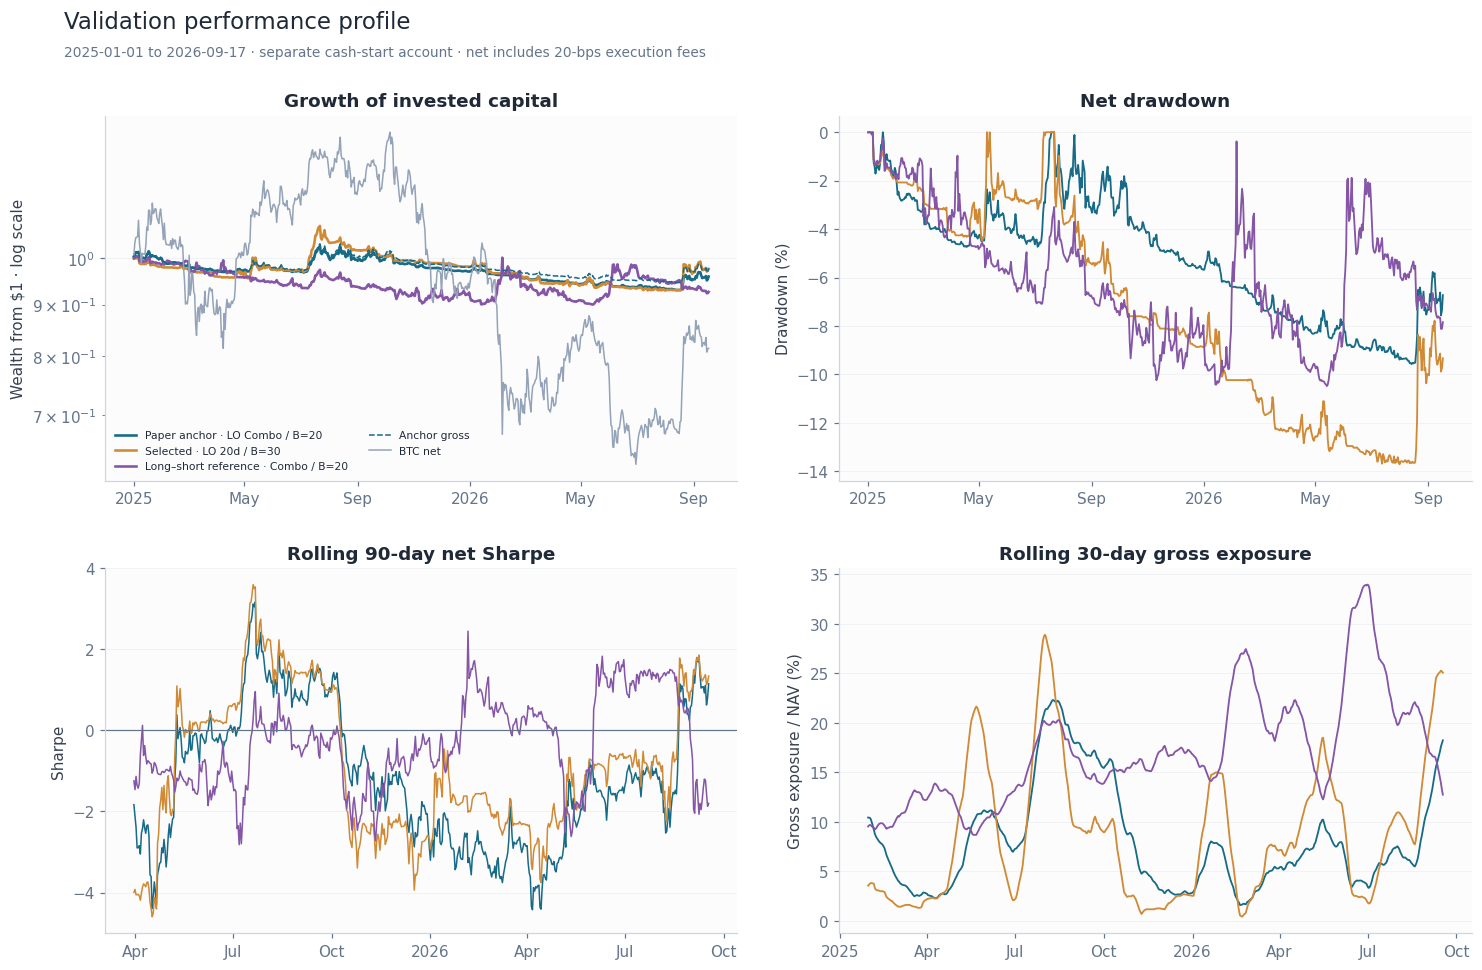

### Backtest: benchmark net performance

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
Benchmark,,,,,,,,,,,,
BTC buy-and-hold,216.7963,33.4120,61.8793,0.6439,1.1509,-76.6346,49.8630,0.5016,-0.0982,-1.4167,-0.2342,0.0378
30-coin buy-and-hold,845.3475,75.3468,87.1301,0.9045,1.5543,-89.6841,54.4521,0.4979,41.1530,1.2370,-24.1047,106.4107


,Alpha vs BTC (%),Beta vs BTC,Alpha HAC p,Information ratio,Skewness,Pearson kurtosis
Benchmark,,,,,,
BTC buy-and-hold,-0.0982,0.9999,0.1568,-0.6623,0.1226,6.4031
30-coin buy-and-hold,41.1530,1.1172,0.2163,0.7761,-0.4243,7.6699


### Validation: benchmark net performance

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover,Alpha vs BTC (%),Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%)
Benchmark,,,,,,,,,,,,
BTC buy-and-hold,-18.5493,-11.2920,43.6774,-0.0466,-0.0802,-53.0600,49.2800,1.1688,-0.2352,-1.4156,-0.5614,0.0911
30-coin buy-and-hold,-56.0327,-38.1146,62.6899,-0.3728,-0.6123,-71.3340,49.7600,1.1871,-25.4290,-1.0972,-70.9441,20.0860


,Alpha vs BTC (%),Beta vs BTC,Alpha HAC p,Information ratio,Skewness,Pearson kurtosis
Benchmark,,,,,,
BTC buy-and-hold,-0.2352,0.9999,0.1574,-1.0827,0.0739,7.8025
30-coin buy-and-hold,-25.4290,1.2201,0.2730,-0.7704,-0.2864,6.8914


In [13]:
short_key=spec_key(make_spec("LS"))
focus_keys=list(dict.fromkeys([anchor_key,selected_key,short_key]))
focus_labels={anchor_key:"Paper anchor · LO Combo / B=20",short_key:"Long–short reference · Combo / B=20"}
selected_model_label=specifications[selected_key]["model"]+("d" if specifications[selected_key]["model"]!="Combo" else "")
focus_labels[selected_key] = (focus_labels.get(selected_key, "")+" · backtest-selected") if selected_key==anchor_key else f'Selected · LO {selected_model_label} / B={specifications[selected_key]["breadth"]}'
focus_colors={anchor_key:COLORS["anchor"],selected_key:COLORS["selected"],short_key:COLORS["short"]}
benchmark_results={}; benchmark_rows=[]; detailed_results={}
for period,dates in PERIOD_DATES.items():
    for label,inds in [("BTC buy-and-hold",[BTC_I]),("30-coin buy-and-hold",list(range(30)))]:
        shape=(len(dates),30); membership=np.zeros(shape,bool); membership[:,inds]=True
        frame,_=simulate_account(np.ones(shape),np.zeros(shape,bool),membership,np.zeros(len(dates),bool),
                                 returns.loc[dates].to_numpy(),dates,len(inds),threshold=np.inf)
        benchmark_results[(period,label)]=frame
        for basis in ["gross","net"]:
            benchmark_rows.append({"Period":period,"Benchmark":label,"Basis":basis,
                **performance(frame[basis],returns.loc[dates,"BTC-USD"]),
                "Annual turnover":365*frame.asset_turnover.mean()})
    for key in focus_keys:
        rerun,details=simulate_spec(specifications[key],dates,keep=True)
        if not np.allclose(rerun.net,results[(period,key)].net): raise AssertionError("Detail rerun differs")
        detailed_results[(period,key)]=details
    display(Markdown(f"### {period}: standardized net performance"))
    display(table_for(focus_keys,period,"net",[focus_labels[k] for k in focus_keys],CORE_METRICS))
    display(Markdown("**Distribution and benchmark diagnostics**"))
    display(table_for(focus_keys,period,"net",[focus_labels[k] for k in focus_keys],INSTITUTIONAL_METRICS))
    fig,axes=plt.subplots(2,2,figsize=(14,9))
    for key in focus_keys:
        frame=results[(period,key)]; color=focus_colors[key]
        wealth,dd=wealth_and_drawdown(frame.net)
        axes[0,0].plot(dates,wealth,color=color,label=focus_labels[key],lw=1.7)
        axes[0,1].plot(dates,dd*100,color=color,lw=1.2)
        rolling=frame.net.rolling(90,min_periods=90)
        axes[1,0].plot(dates,np.sqrt(SHARPE_PERIODS_PER_YEAR)*rolling.mean()/rolling.std(),color=color,lw=1)
        axes[1,1].plot(dates,100*frame.gross_exposure.rolling(30,min_periods=30).mean(),color=color,lw=1.2)
    axes[0,0].plot(dates,(1+results[(period,anchor_key)].gross).cumprod(),color=COLORS["anchor"],ls="--",lw=1,label="Anchor gross")
    axes[0,0].plot(dates,(1+benchmark_results[(period,"BTC buy-and-hold")].net).cumprod(),color=COLORS["btc"],lw=1,label="BTC net")
    axes[0,0].set_yscale("log"); axes[0,0].set_ylabel("Wealth from $1 · log scale")
    axes[0,0].legend(fontsize=7,ncol=2)
    for ax,title,ylabel in [(axes[0,0],"Growth of invested capital","Wealth from $1 · log scale"),
        (axes[0,1],"Net drawdown","Drawdown (%)"),(axes[1,0],"Rolling 90-day net Sharpe","Sharpe"),
        (axes[1,1],"Rolling 30-day gross exposure","Gross exposure / NAV (%)")]:
        ax.set_title(title); ax.set_ylabel(ylabel); polish_axis(ax,date_axis=True)
    axes[1,0].axhline(0,color="#64748b",lw=.8)
    show_figure(fig,f"{period.lower()}_performance",f"{period} performance profile",f"{dates[0].date()} to {dates[-1].date()} · separate cash-start account · net includes 20-bps execution fees")

benchmark_metrics=pd.DataFrame(benchmark_rows).set_index(["Period","Benchmark","Basis"])
for period in PERIOD_DATES:
    benchmark_net=benchmark_metrics.xs((period,"net"),level=("Period","Basis"))
    display(Markdown(f"### {period}: benchmark net performance"))
    display(benchmark_net[CORE_METRICS])
    display(benchmark_net[INSTITUTIONAL_METRICS])


### Backtest-to-validation comparison

`Selected in backtest` is `True` only for the strategy chosen using backtest data and then carried unchanged into validation; it does not indicate validation success.

The table and chart show the same 15 primary-grid strategies, sorted by validation Sharpe. `B`
denotes maximum monthly basket breadth, while `LO` denotes long-only and `LS` denotes long-short.


,Backtest Sharpe,Validation Sharpe,Sharpe change,Selected in backtest
Strategy,,,,
LO · B=5 · 20d,0.4495,0.2316,-0.2179,False
LO · B=5 · 60d,0.3639,0.1664,-0.1976,False
LO · B=5 · 30d,0.2864,0.1589,-0.1275,False
LO · B=5 · 90d,0.4014,0.1580,-0.2434,False
LO · B=5 · 10d,0.4789,0.0470,-0.4320,False
LO · B=5 · 150d,0.3547,0.0095,-0.3452,False
LO · B=5 · Combo,0.4586,-0.0006,-0.4592,False
LO · B=10 · 20d,0.8857,-0.0138,-0.8994,False
LO · B=10 · 30d,0.6749,-0.0267,-0.7016,False


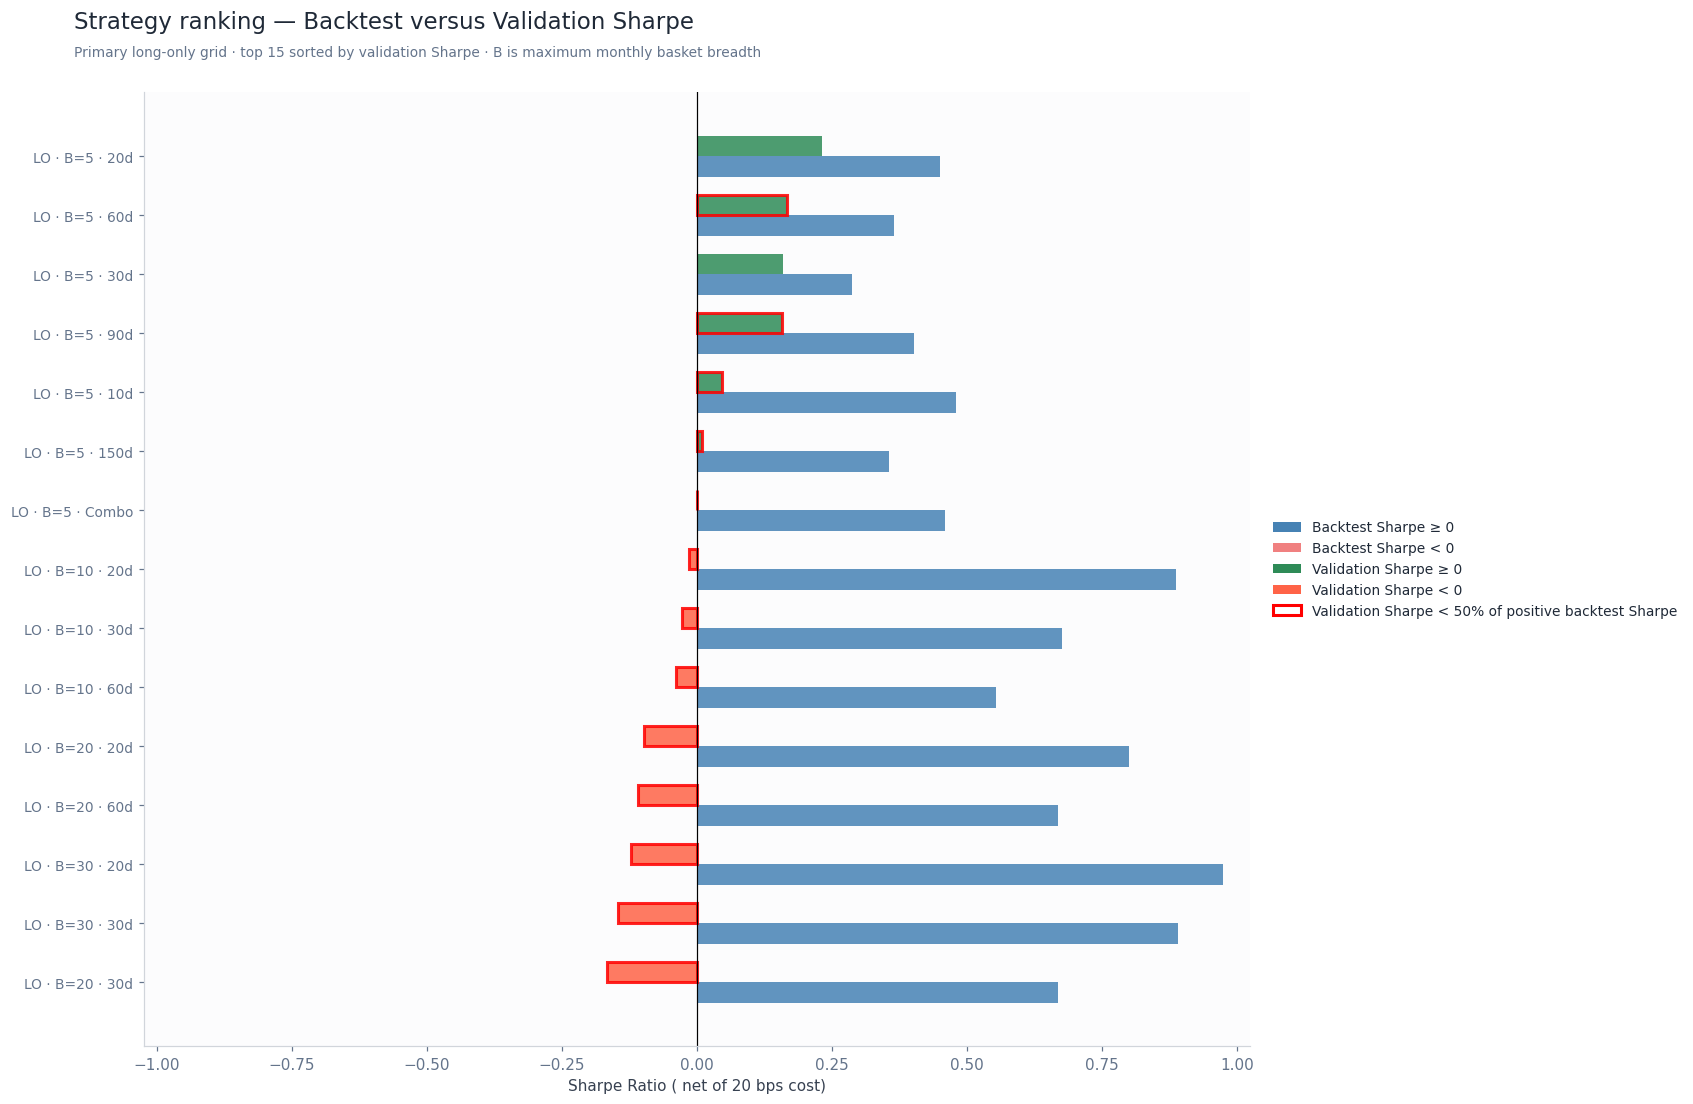

In [14]:
comparison_rows=[]
for key in primary_grid:
    spec=specifications[key]
    model_label="Combo" if spec["model"]=="Combo" else f"{spec['model']}d"
    label=f"{spec['direction']} · B={spec['breadth']} · {model_label}"
    backtest_sharpe=metrics.loc[("Backtest",key,"net"),"Sharpe"]
    validation_sharpe=metrics.loc[("Validation",key,"net"),"Sharpe"]
    comparison_rows.append({"Strategy":label,"Backtest Sharpe":backtest_sharpe,
        "Validation Sharpe":validation_sharpe,"Sharpe change":validation_sharpe-backtest_sharpe,
        "Selected in backtest":key==selected_key})
generalization_table=pd.DataFrame(comparison_rows).set_index("Strategy")
comparison=(generalization_table
            .sort_values("Validation Sharpe",ascending=False)
            .head(15))
display(comparison)

# Horizontal comparison uses the same ordering and rows as the table above.
y=np.arange(len(comparison))
bar_height=0.35
fig,ax=plt.subplots(figsize=(16,max(7,0.55*len(comparison)+2)))
backtest_colors=["steelblue" if value>=0 else "lightcoral" for value in comparison["Backtest Sharpe"]]
validation_colors=["seagreen" if value>=0 else "tomato" for value in comparison["Validation Sharpe"]]
ax.barh(y+bar_height/2,comparison["Backtest Sharpe"].to_numpy(),bar_height,
        color=backtest_colors,label="Backtest (2021–2024)",alpha=0.85)
validation_bars=ax.barh(y-bar_height/2,comparison["Validation Sharpe"].to_numpy(),bar_height,
                        color=validation_colors,label="Validation (2025–2026)",alpha=0.85)

# Red borders flag a validation Sharpe below half of a positive backtest Sharpe.
for bar,backtest_value,validation_value in zip(
        validation_bars,comparison["Backtest Sharpe"],comparison["Validation Sharpe"]):
    if backtest_value>0 and validation_value<0.5*backtest_value:
        bar.set_edgecolor("red")
        bar.set_linewidth(2.0)

ax.set_yticks(y)
ax.set_yticklabels(comparison.index,fontsize=9)
ax.invert_yaxis()
# Use equal positive and negative ranges so the zero line is visually centered.
sharpe_limit=1.05*np.nanmax(np.abs(comparison[["Backtest Sharpe","Validation Sharpe"]].to_numpy()))
ax.set_xlim(-sharpe_limit,sharpe_limit)
ax.axvline(0,color="black",linewidth=0.8)
ax.set_xlabel("Sharpe Ratio ( net of 20 bps cost)")
from matplotlib.patches import Patch
legend_handles=[
    Patch(facecolor="steelblue",label="Backtest Sharpe ≥ 0"),
    Patch(facecolor="lightcoral",label="Backtest Sharpe < 0"),
    Patch(facecolor="seagreen",label="Validation Sharpe ≥ 0"),
    Patch(facecolor="tomato",label="Validation Sharpe < 0"),
    Patch(facecolor="none",edgecolor="red",linewidth=2,
          label="Validation Sharpe < 50% of positive backtest Sharpe"),
]
ax.legend(handles=legend_handles,loc="center left",bbox_to_anchor=(1.01,0.5),fontsize=9)
show_figure(fig,"strategy_train_validation_sharpe",
            "Strategy ranking — Backtest versus Validation Sharpe",
            "Primary long-only grid · top 15 sorted by validation Sharpe · B is maximum monthly basket breadth")


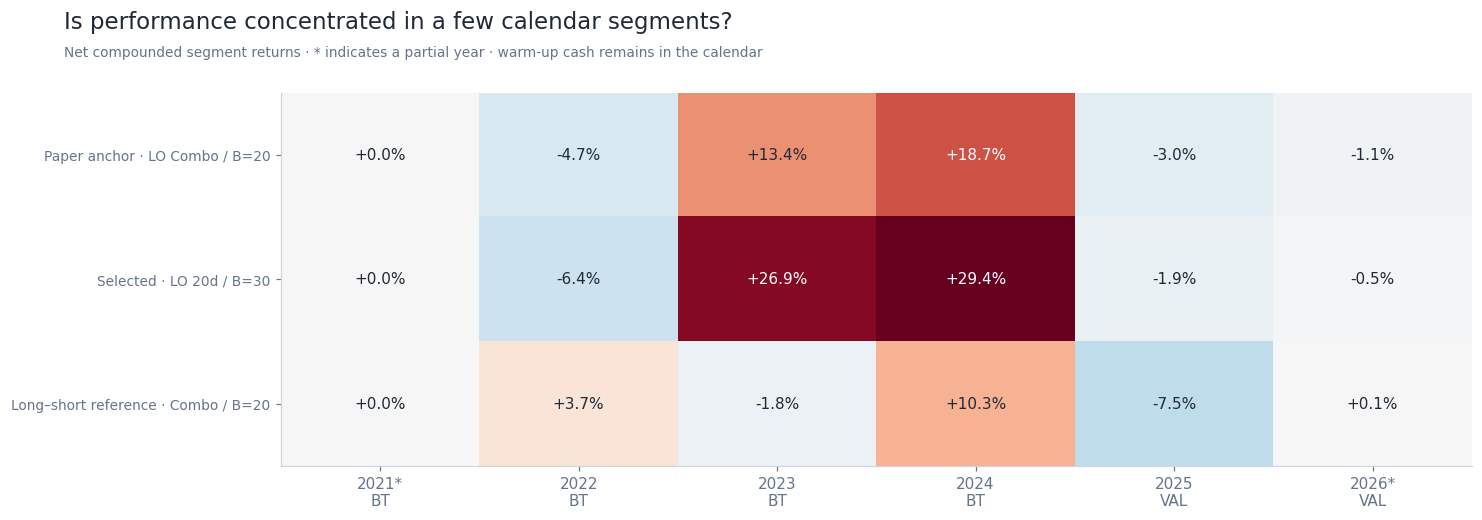

In [15]:
calendar_rows=[]
for (period,key),frame in results.items():
    if key not in focus_keys: continue
    for year,chunk in frame.groupby(frame.index.year):
        calendar_rows.append({"Period":period,"Year":year,"Strategy":key,"N dates":len(chunk),
                              "Net return (%)":100*((1+chunk.net).prod()-1)})
calendar_returns=pd.DataFrame(calendar_rows).set_index(["Period","Year","Strategy"]).sort_index()
wide=calendar_returns["Net return (%)"].unstack("Strategy").reindex(columns=focus_keys)
fig,ax=plt.subplots(figsize=(14,4.8))
values=wide.to_numpy().T; bound=max(abs(values).max(),1)
ax.imshow(values,cmap="RdBu_r",vmin=-bound,vmax=bound,aspect="auto")
for (r,c),v in np.ndenumerate(values):
    ax.text(c,r,f"{v:+.1f}%",ha="center",va="center",color="white" if abs(v)>.6*bound else "#1f2937",fontsize=10)
labels=[]
for period,year in wide.index:
    n=calendar_returns.loc[(period,year)].iloc[0]["N dates"]
    expected=366 if pd.Timestamp(year,12,31).is_leap_year else 365
    labels.append(f"{year}{'*' if n!=expected else ''}\n{'BT' if period=='Backtest' else 'VAL'}")
ax.set_xticks(range(len(labels)),labels); ax.set_yticks(range(len(focus_keys)),[focus_labels[k] for k in focus_keys],fontsize=9)
show_figure(fig,"calendar_returns","Is performance concentrated in a few calendar segments?","Net compounded segment returns · * indicates a partial year · warm-up cash remains in the calendar")

## 9. Reproducible research outputs

Export the complete experiment registry, frozen backtest choice, all gross/net daily returns
and metrics, signal-trade diagnostics, monthly eligibility audit, figure files, and actual
holdings/trades for the primary comparisons. All asset-level primary exports retain 30 columns.
Input checksums, model rules, date boundaries, software versions, and source hash identify
the run. Research outputs go directly to `output/catching_crypto_trends/` beside the notebook. Existing files with the same names are overwritten on each run.

In [16]:
specification={"study":"zarattini_donchian_momentum_channels","assets":ASSETS,
    "sample_start":SAMPLE_START,"sample_end":SAMPLE_END,
    "backtest_start":BACKTEST_START,"backtest_end":BACKTEST_END,
    "validation_start":VALIDATION_START,"validation_end":VALIDATION_END,
    "lookbacks":LOOKBACKS,"target_vol":TARGET_VOL,"vol_window":VOL_WINDOW,"max_leverage":MAX_LEVERAGE,
    "cost_bps":COST_BPS,"threshold":REBALANCE_THRESHOLD,"threshold_denominator":"current marked-to-market weight",
    "stop_timing":"prior-close stop; current midpoint updates next stop","history_age_proxy_days":MIN_HISTORY_DAYS,
    "warmup":"common 360 closes; rotating baskets additionally require 365 observed elapsed days",
    "entry_volume":ENTRY_VOLUME,"exit_volume":EXIT_VOLUME,"exit_abs_move":EXIT_MOVE,
    "monthly_ranking":"calendar-month median volume","accounting":"monthly equal capital; intra-month asset units and sleeve equity drift",
    "missing_slots":"unallocated cash","net_basis":"same executed exposures, actual fees and segment liquidation",
    "input_sha256":input_hashes,"experiments":specifications}
OUTPUT_DIR=OUTPUT_ROOT
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
daily_export=pd.concat(results,names=["Period","Strategy","Return date"])
for name,obj in {"metrics":metrics,"daily_returns_and_costs":daily_export,"backtest_grid_ranking":training_ranking,
    "volume_issues":volume_issues,"threshold_comparison":threshold_table,
    "unit_trade_ledger":unit_trade_ledger,"unit_trade_summary":unit_trade_summary,"benchmark_metrics":benchmark_metrics,
    "generalization":generalization_table,"calendar_returns":calendar_returns,
    "monthly_selection_audit":selection_audit}.items():
    suffix=".csv.gz" if name=="daily_returns_and_costs" else ".csv"
    obj.to_csv(OUTPUT_DIR/f"{name}{suffix}")
pd.concat(benchmark_results,names=["Period","Benchmark","Return date"]).to_csv(OUTPUT_DIR/"benchmark_daily_returns.csv.gz")
for name in ["holding_weights","asset_pnl","asset_fees","formation_trades","final_liquidation_trades"]:
    pd.concat({k:v[name] for k,v in detailed_results.items()},names=["Period","Strategy","Return date"]).to_csv(OUTPUT_DIR/f"primary_{name}.csv")
pd.DataFrame(main_membership,index=prices.index,columns=ASSETS).to_csv(OUTPUT_DIR/"anchor_formation_membership.csv")
pd.DataFrame(targets[("LO","Combo")],index=prices.index,columns=ASSETS).to_csv(OUTPUT_DIR/"combo_formation_targets.csv")
(OUTPUT_DIR/"frozen_selection.json").write_text(json.dumps(frozen_selection,indent=2))
manifest={"specification":specification,"selection":frozen_selection,
    "environment":{"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,"statsmodels":sm.__version__},
    "figures":list(FIGURES),"validation_previously_explored":True,
    "notebook_source_sha256":hashlib.sha256(json.dumps([c["source"] for c in json.loads((NOTEBOOK_DIR/NOTEBOOK_NAME).read_text())["cells"]],sort_keys=True).encode()).hexdigest()}
(OUTPUT_DIR/"manifest.json").write_text(json.dumps(manifest,indent=2))
for name,fig in FIGURES.items(): fig.savefig(OUTPUT_DIR/f"{name}.png",dpi=160,bbox_inches="tight")
print(f"Saved {len(specifications)} configurations per segment and {len(FIGURES)} figures to {OUTPUT_DIR.relative_to(NOTEBOOK_DIR).as_posix()}/")

Saved 135 configurations per segment and 9 figures to output/catching_crypto_trends/


## 10. Core findings and interpretation

The summary below is generated from this run's frozen selection and exported performance tables. It compares the backtest-selected configuration with the paper-style 20-coin Combo under the declared manual dates. Validation is reported without changing the frozen choice; a high validation rank is a retrospective observation.

The fixed 30-coin universe, common signal warm-up, vendor prices and volumes, and 20-bps fee constrain interpretation. Empty basket slots and stopped-out accounts remain in cash. The 25% volatility target applies to each active coin model, not to the diversified portfolio as a whole. The rebalance threshold changes both costs and exposure, so its sensitivity is not a pure fee comparison.


In [17]:
# Generate the conclusion from current exports so date changes cannot leave stale results.
conclusion_selection = json.loads((OUTPUT_DIR / "frozen_selection.json").read_text())
conclusion_metrics = pd.read_csv(OUTPUT_DIR / "metrics.csv")
conclusion_key = conclusion_selection["selected_strategy"]
conclusion_spec = conclusion_selection["selected_specification"]
display(Markdown(
    f"**Frozen backtest choice:** {conclusion_spec['model']}-day, "
    f"{conclusion_spec['direction']}, breadth {conclusion_spec['breadth']}. "
    f"Selected from {conclusion_selection['candidate_count']} candidates using backtest net Sharpe. "
    f"Backtest: {BACKTEST_START}–{BACKTEST_END}; validation: {VALIDATION_START}–{VALIDATION_END}."))
conclusion_rows = conclusion_metrics.loc[
    conclusion_metrics.Basis.eq("net") & conclusion_metrics.Strategy.isin([
        conclusion_key, "rotating_20_LO_Combo_T20_R0", "rotating_20_LS_Combo_T20_R0"])]
display(conclusion_rows[["Period", "Strategy", "CAGR (%)", "Sharpe",  "Alpha HAC t", "Alpha 95% CI low (%)", "Alpha 95% CI high (%)", "Max drawdown (%)"]].round(3))
display(Markdown("**Validation observations, without reselection:** highest net Sharpe in each displayed period."))
conclusion_best = conclusion_metrics.loc[conclusion_metrics.Basis.eq("net")].sort_values("Sharpe", ascending=False).groupby("Period", sort=False).head(1)
display(conclusion_best[["Period", "Strategy", "CAGR (%)", "Sharpe",  "Alpha HAC t", "Alpha 95% CI low (%)", "Alpha 95% CI high (%)", "Max drawdown (%)"]].round(3))


**Frozen backtest choice:** 20-day, LO, breadth 30. Selected from 40 candidates using backtest net Sharpe. Backtest: 2021-01-02–2024-12-31; validation: 2025-01-01–2026-09-17.

,Period,Strategy,CAGR (%),Sharpe,Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%),Max drawdown (%)
59,Backtest,rotating_20_LO_Combo_T20_R0,6.4380,0.7600,1.0260,-3.8680,12.3560,-8.1620
65,Backtest,rotating_30_LO_20_T20_R0,11.3430,0.9740,1.3730,-3.7350,21.1600,-11.8560
207,Backtest,rotating_20_LS_Combo_T20_R0,2.9560,0.3000,1.0480,-4.3860,14.4580,-15.0740
329,Validation,rotating_20_LO_Combo_T20_R0,-2.3930,-0.3310,-0.6650,-8.3290,4.1170,-9.5730
335,Validation,rotating_30_LO_20_T20_R0,-1.3980,-0.1220,-0.1730,-11.8260,9.9120,-13.7080
477,Validation,rotating_20_LS_Combo_T20_R0,-4.3670,-0.3070,-0.7780,-14.9670,6.4750,-10.4780


**Validation observations, without reselection:** highest net Sharpe in each displayed period.

,Period,Strategy,CAGR (%),Sharpe,Alpha HAC t,Alpha 95% CI low (%),Alpha 95% CI high (%),Max drawdown (%)
65,Backtest,rotating_30_LO_20_T20_R0,11.3430,0.9740,1.3730,-3.7350,21.1600,-11.8560
429,Validation,single_BTC_LS_60_T20_R0,5.4990,0.2900,0.4990,-21.9730,36.9520,-16.9660
